# 3.3.0-Clustering Level 2

**Inés Sentís**

Date of execution

In [1]:
Sys.Date()

[1] "2025-11-27"

## Libraries

In [2]:
options(warn = -1, verbose = FALSE)
suppressMessages(suppressWarnings({
library(Signac)
library(Seurat)
library(tidyverse)
library(ggplot2)
library(gridExtra)
library(scran)
library(scater)
}))

## Parameters

In [3]:
patient <- "p5"
subproj <- "AVGUSTINOVA_02_03"

assay_ch <- "RNA_decontx"

In [4]:
source(here::here(glue::glue("{subproj}/multiome_analysis/misc/paths.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/style.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/variables.R")))
source(here::here(glue::glue("utils/bin.R")))

"{clust}/{plt_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

"{clust}/{robj_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

set.seed(0)

In [5]:
var_name <- paste0("colors_", patient)
colors_list <- get(var_name)

In [6]:
var_name <- paste0("comp_", patient)
dcomp <- get(var_name)
dcomp

$rna
 [1]  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20

$atac
 [1]  2  3  4  5  6  7  8  9 10 11 12 13 14 15

In [7]:
var_name <- paste0("topc_", patient)
top_counts <- get(var_name)
top_counts

[1] "ERBB4"    "ANK2"     "CACNA2D1" "MALAT1"   "MACROD2"

In [8]:
var_name <- paste0("reso_l1_", patient)
reso <- get(var_name)
reso

[1] 0.1

## Load data

In [9]:
seurat_obj <- readRDS(here::here(glue::glue("{clust}/{robj_dir}/level_1/3.2.0-l1_anno_{patient}.rds")))
DefaultAssay(seurat_obj) <- assay_ch

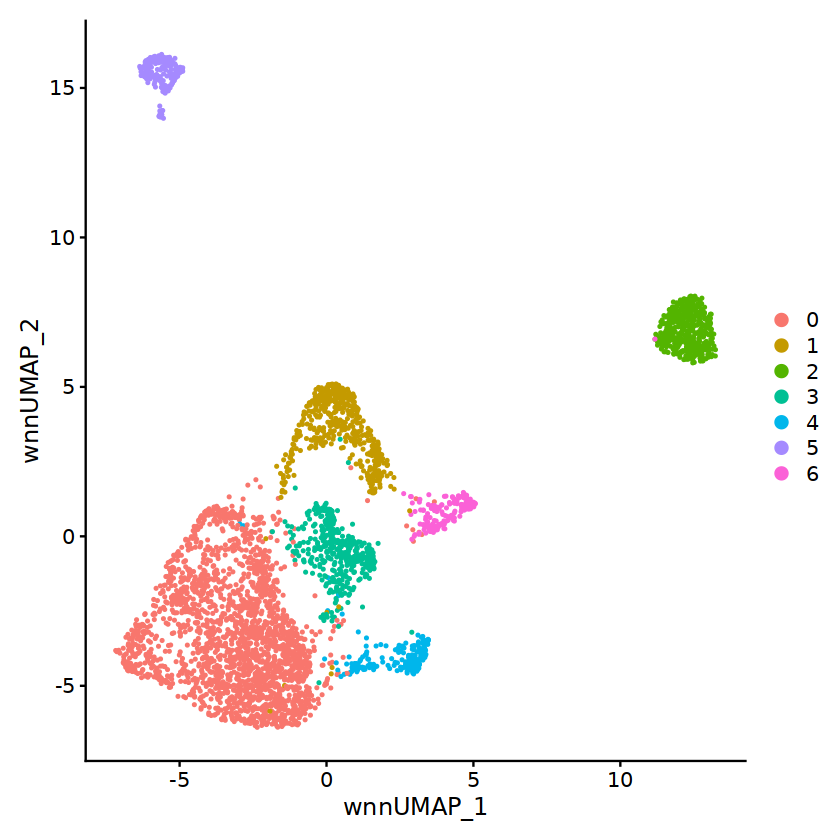

In [10]:
DimPlot(seurat_obj, reduction = "wnn.umap") 

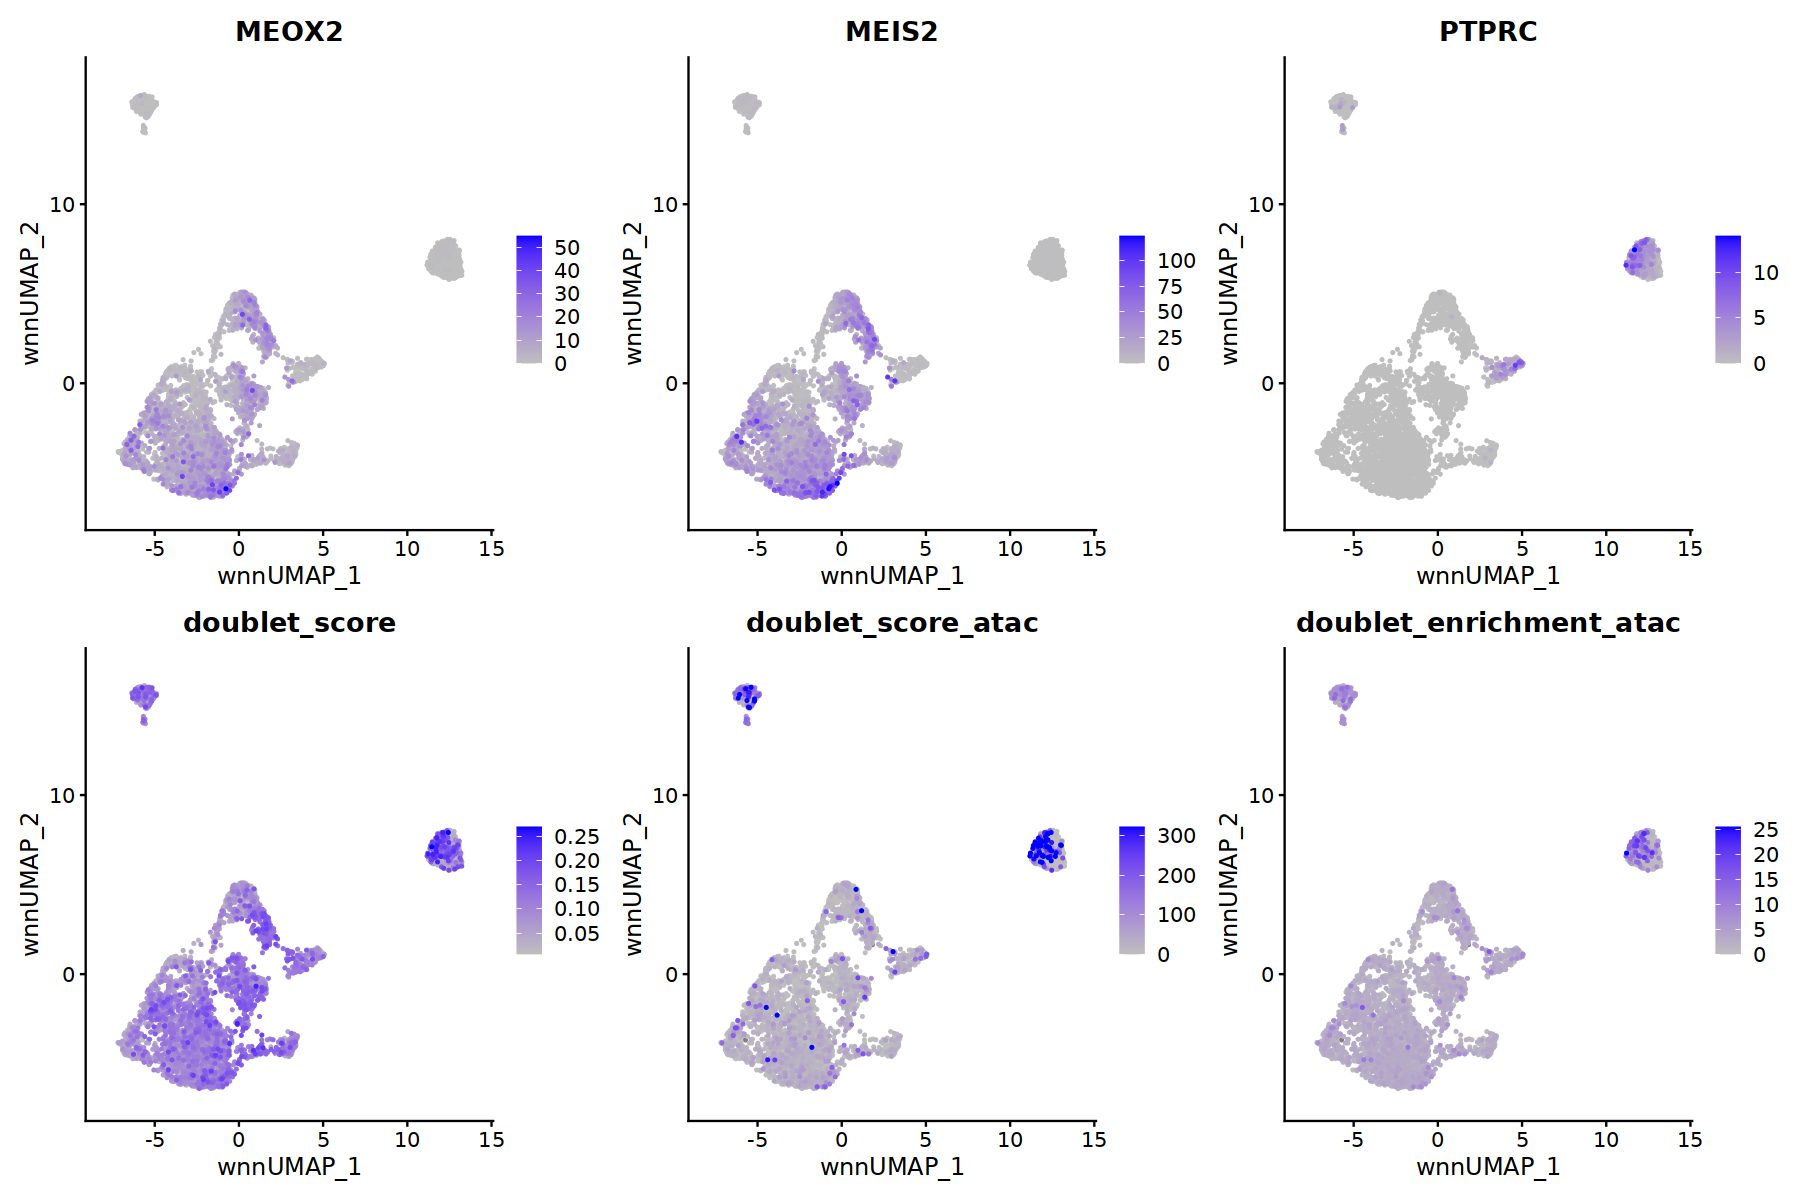

In [11]:
options(repr.plot.width = 15, repr.plot.height = 10)
FeaturePlot(seurat_obj, reduction = "wnn.umap", 
            feature=c("MEOX2","MEIS2","PTPRC",
                      "doublet_score","doublet_score_atac","doublet_enrichment_atac"), 
            ncol=3,cols = c("gray", "blue"),  order=T)

## Re-normalize

In [12]:
DefaultAssay(seurat_obj) <- assay_ch

In [13]:
keep_genes <- data.frame(rowSums(as.matrix(seurat_obj[[assay_ch]]@counts)) != 0)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
seurat_obj[[assay_ch]]@counts <- seurat_obj[[assay_ch]]@counts[rownames(keep_genes), ]
seurat_obj[[assay_ch]]@data <- seurat_obj[[assay_ch]]@data[rownames(keep_genes), ]

In [14]:
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [15]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj, assay=assay_ch)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

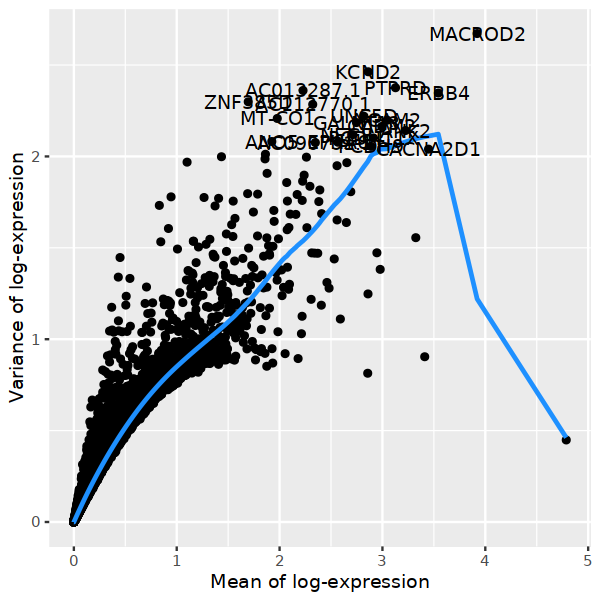

In [16]:
options(repr.plot.width = 5, repr.plot.height = 5)
plt

In [17]:
print(length(hvgs))
hvgs <- setdiff(hvgs, top_counts)
print(length(hvgs))

[1] 4097
[1] 4096


In [18]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  AC112770.1, CHODL, ANO5, AC013287.1, HS6ST3, NLGN1, SDK1, LUZP2, LINC01924, ROR1 
	   DCC, LINC02755, PLEKHH2, KCTD8, MUC16, ZNF385D, MDGA2, AC012355.1, LHFPL3, FSTL5 
	   GABRG3, LINC02742, NEBL, SLIT3, TMEFF2, HDAC9, AL359208.1, ADGRB3, AC079052.1, SPOCK3 
Negative:  DOCK4, ELL2, LDLRAD4, CHST11, HIF1A, UTRN, SLC8A1, FMN1, FOXN3, SLC16A10 
	   PLXDC2, STARD13, IQGAP2, TNS3, ELMO1, TRPS1, UBE2E2, FAM49A, GAB2, KCNMA1 
	   SRGN, ZEB2, ANKH, JARID2, ABCA1, TGFBI, TCF4, SAMSN1, SASH1, IRAK3 
PC_ 2 
Positive:  FMNL2, IQGAP2, FMN1, KCNMA1, SLC16A10, SAMSN1, RGS1, CTSB, SRGN, SLC11A1 
	   KYNU, EPB41L3, ELMO1, MSR1, FAM49A, CD86, GLUL, FRMD4B, MERTK, ZNF331 
	   RAPGEF1, TBXAS1, GNA13, PRKAG2, DAPK1, ANKH, CD163, DOCK2, TGFBI, ACSL1 
Negative:  PRKG1, PTPRG, DLC1, COL4A1, SGIP1, COL4A2, CCDC102B, EBF1, ADGRF5, MYO1B 
	   IGFBP7, FN1, COL12A1, SOX5, EDNRA, COL6A3, ITGA1, PRRX1, EPS8, ARHGAP42 
	   CALD1, COL18A1, GUCY1A2, LAMA4, PDE1A, ADA

In [19]:
markers = c("GPC6","ERBB4", "SOX5","MEOX2","PTPRC")

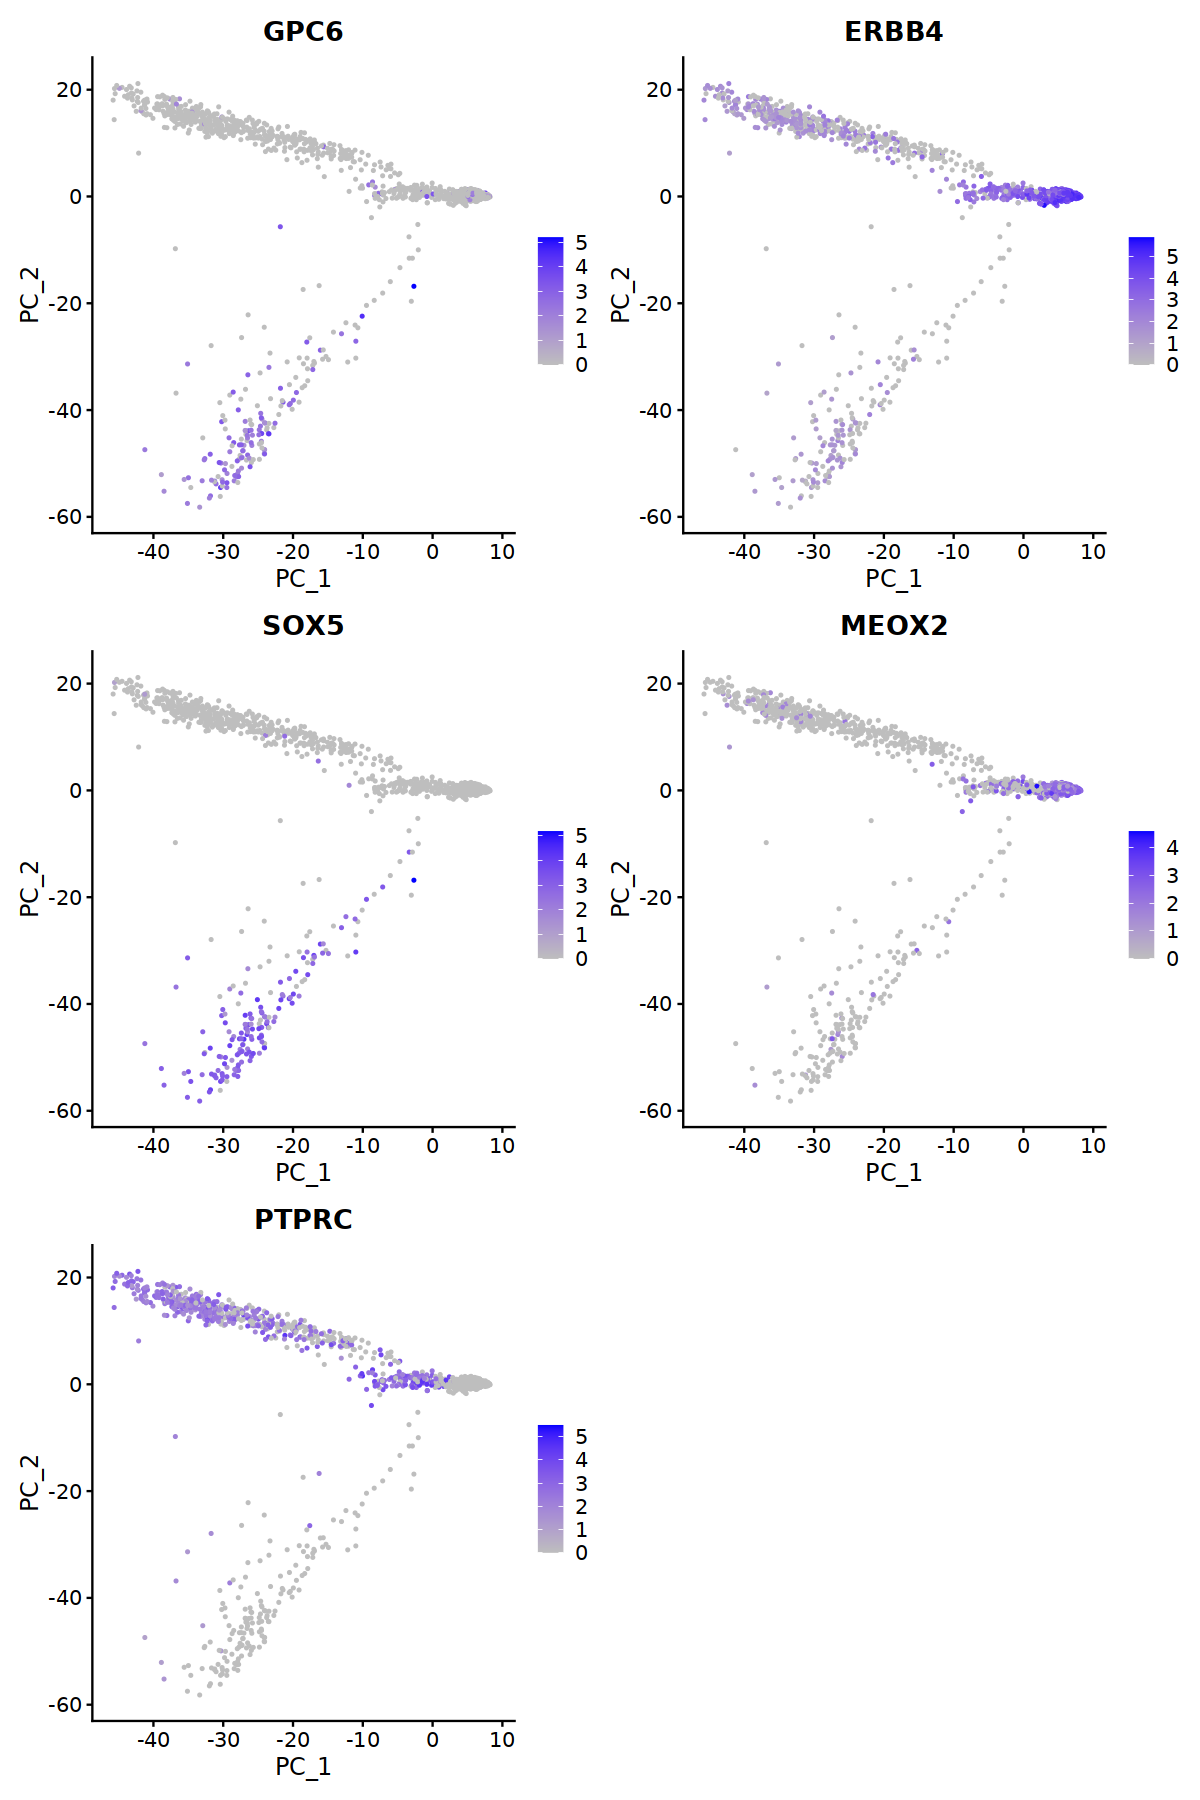

In [20]:
options(repr.plot.width = 10, repr.plot.height = 15)
FeaturePlot(seurat_obj, reduction = "pca", 
            feature=markers, ncol=2,
            cols = c("gray", "blue"),  min.cutoff = 0)

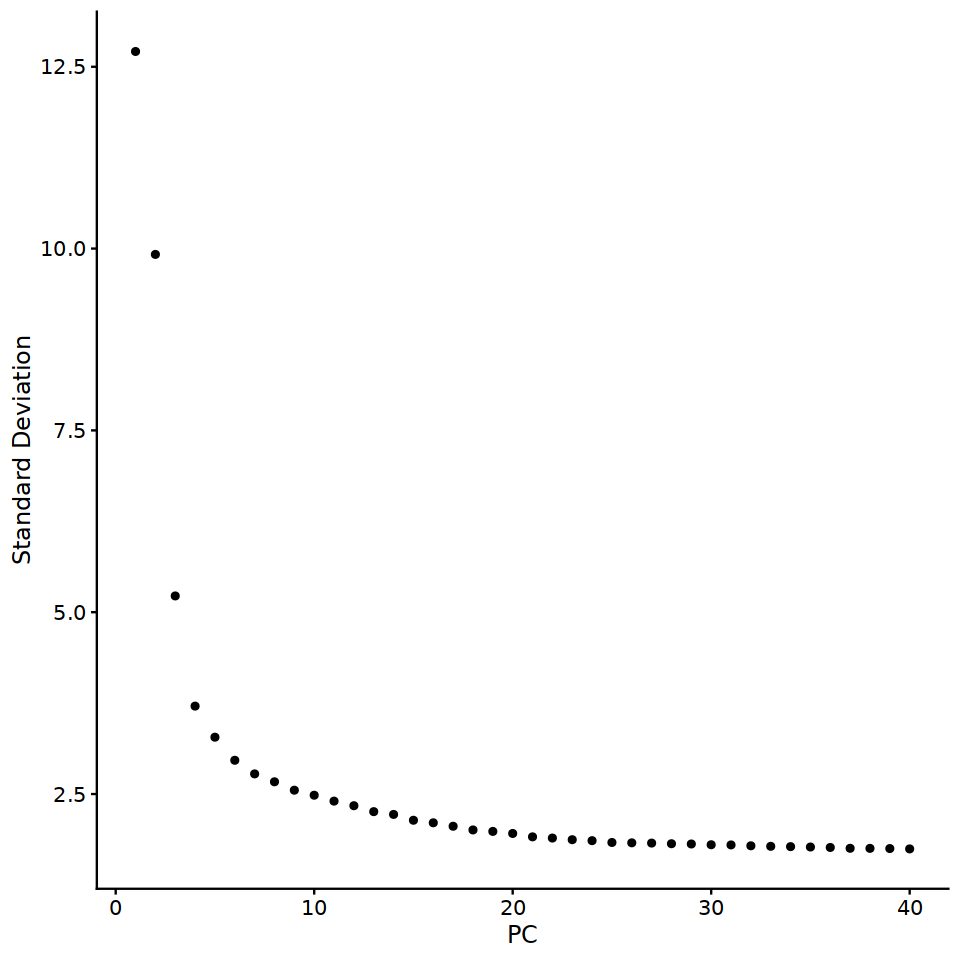

In [21]:
options(repr.plot.width = 8, repr.plot.height = 8)
ElbowPlot(seurat_obj, n=40)

In [22]:
seurat_obj <- RunUMAP(
  seurat_obj,
  dims = dcomp$rna,
  reduction = "pca",
  reduction.key = "rnaUMAP_",
   assay.use = assay_ch,
)

Suggested parameter: assay instead of assay.use


14:10:38 UMAP embedding parameters a = 0.9922 b = 1.112

14:10:38 Read 4099 rows and found 20 numeric columns

14:10:38 Using Annoy for neighbor search, n_neighbors = 30

14:10:38 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:10:38 Writing NN index file to temp file /scratch_tmp/49729482/Rtmp8vEgh6/file920e64612842

14:10:38 Searching Annoy index using 1 thread, search_k = 3000

14:10:39 Annoy recall = 100%

14:10:40 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:10:42 Initializing from normalized Laplacian + noise (using irlba)

14:10:42 Commencing optimization for 500 epochs, with 164788 positive edges

14:10:54 Optimization finished



In [23]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(dcomp$rna, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [24]:
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_",
   n.neighbors = 3, # avoid such compact groups of cells 
   min.dist = 1 # avoid such compact groups of cells 
)

14:11:04 UMAP embedding parameters a = 0.115 b = 1.929

14:11:05 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

14:11:06 Initializing from normalized Laplacian + noise (using irlba)

14:11:07 Commencing optimization for 500 epochs, with 119926 positive edges

14:11:20 Optimization finished



In [25]:
seurat_obj <- Seurat::FindClusters(seurat_obj, resolution = as.numeric(reso),
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 4099
Number of edges: 154912

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9726
Number of communities: 7
Elapsed time: 0 seconds


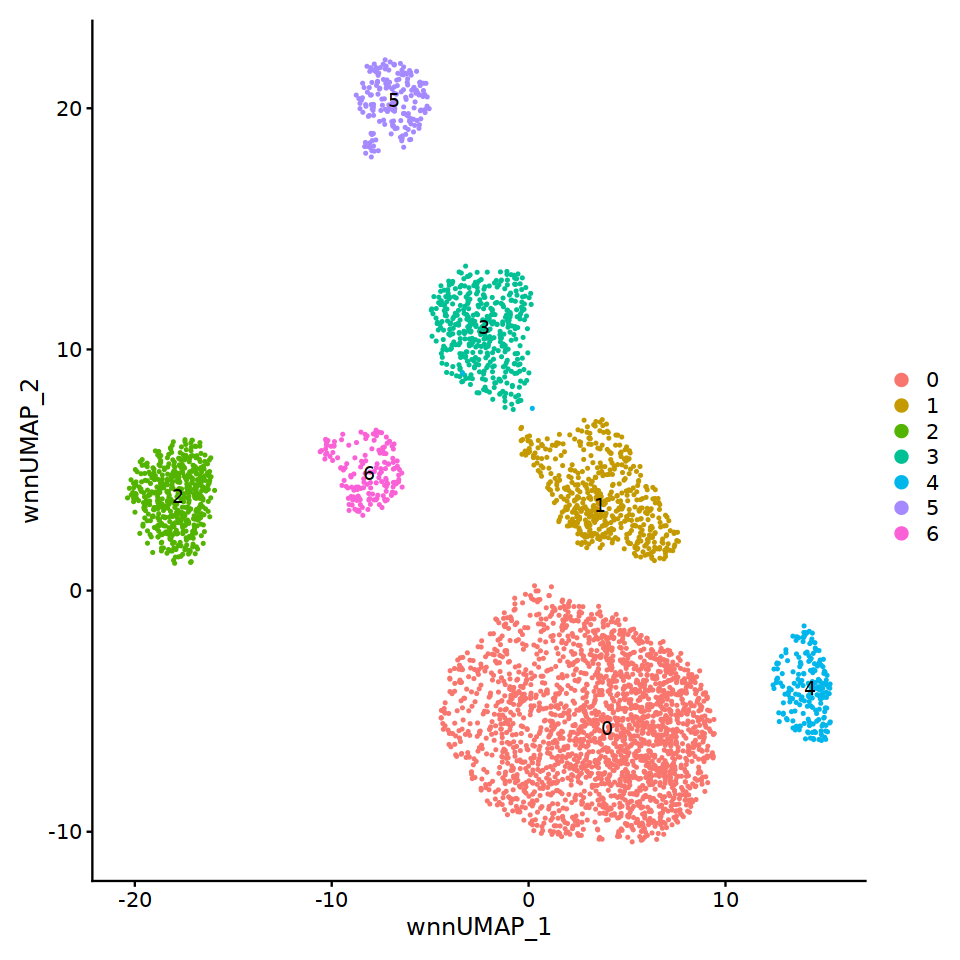

In [26]:
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

In [27]:
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6



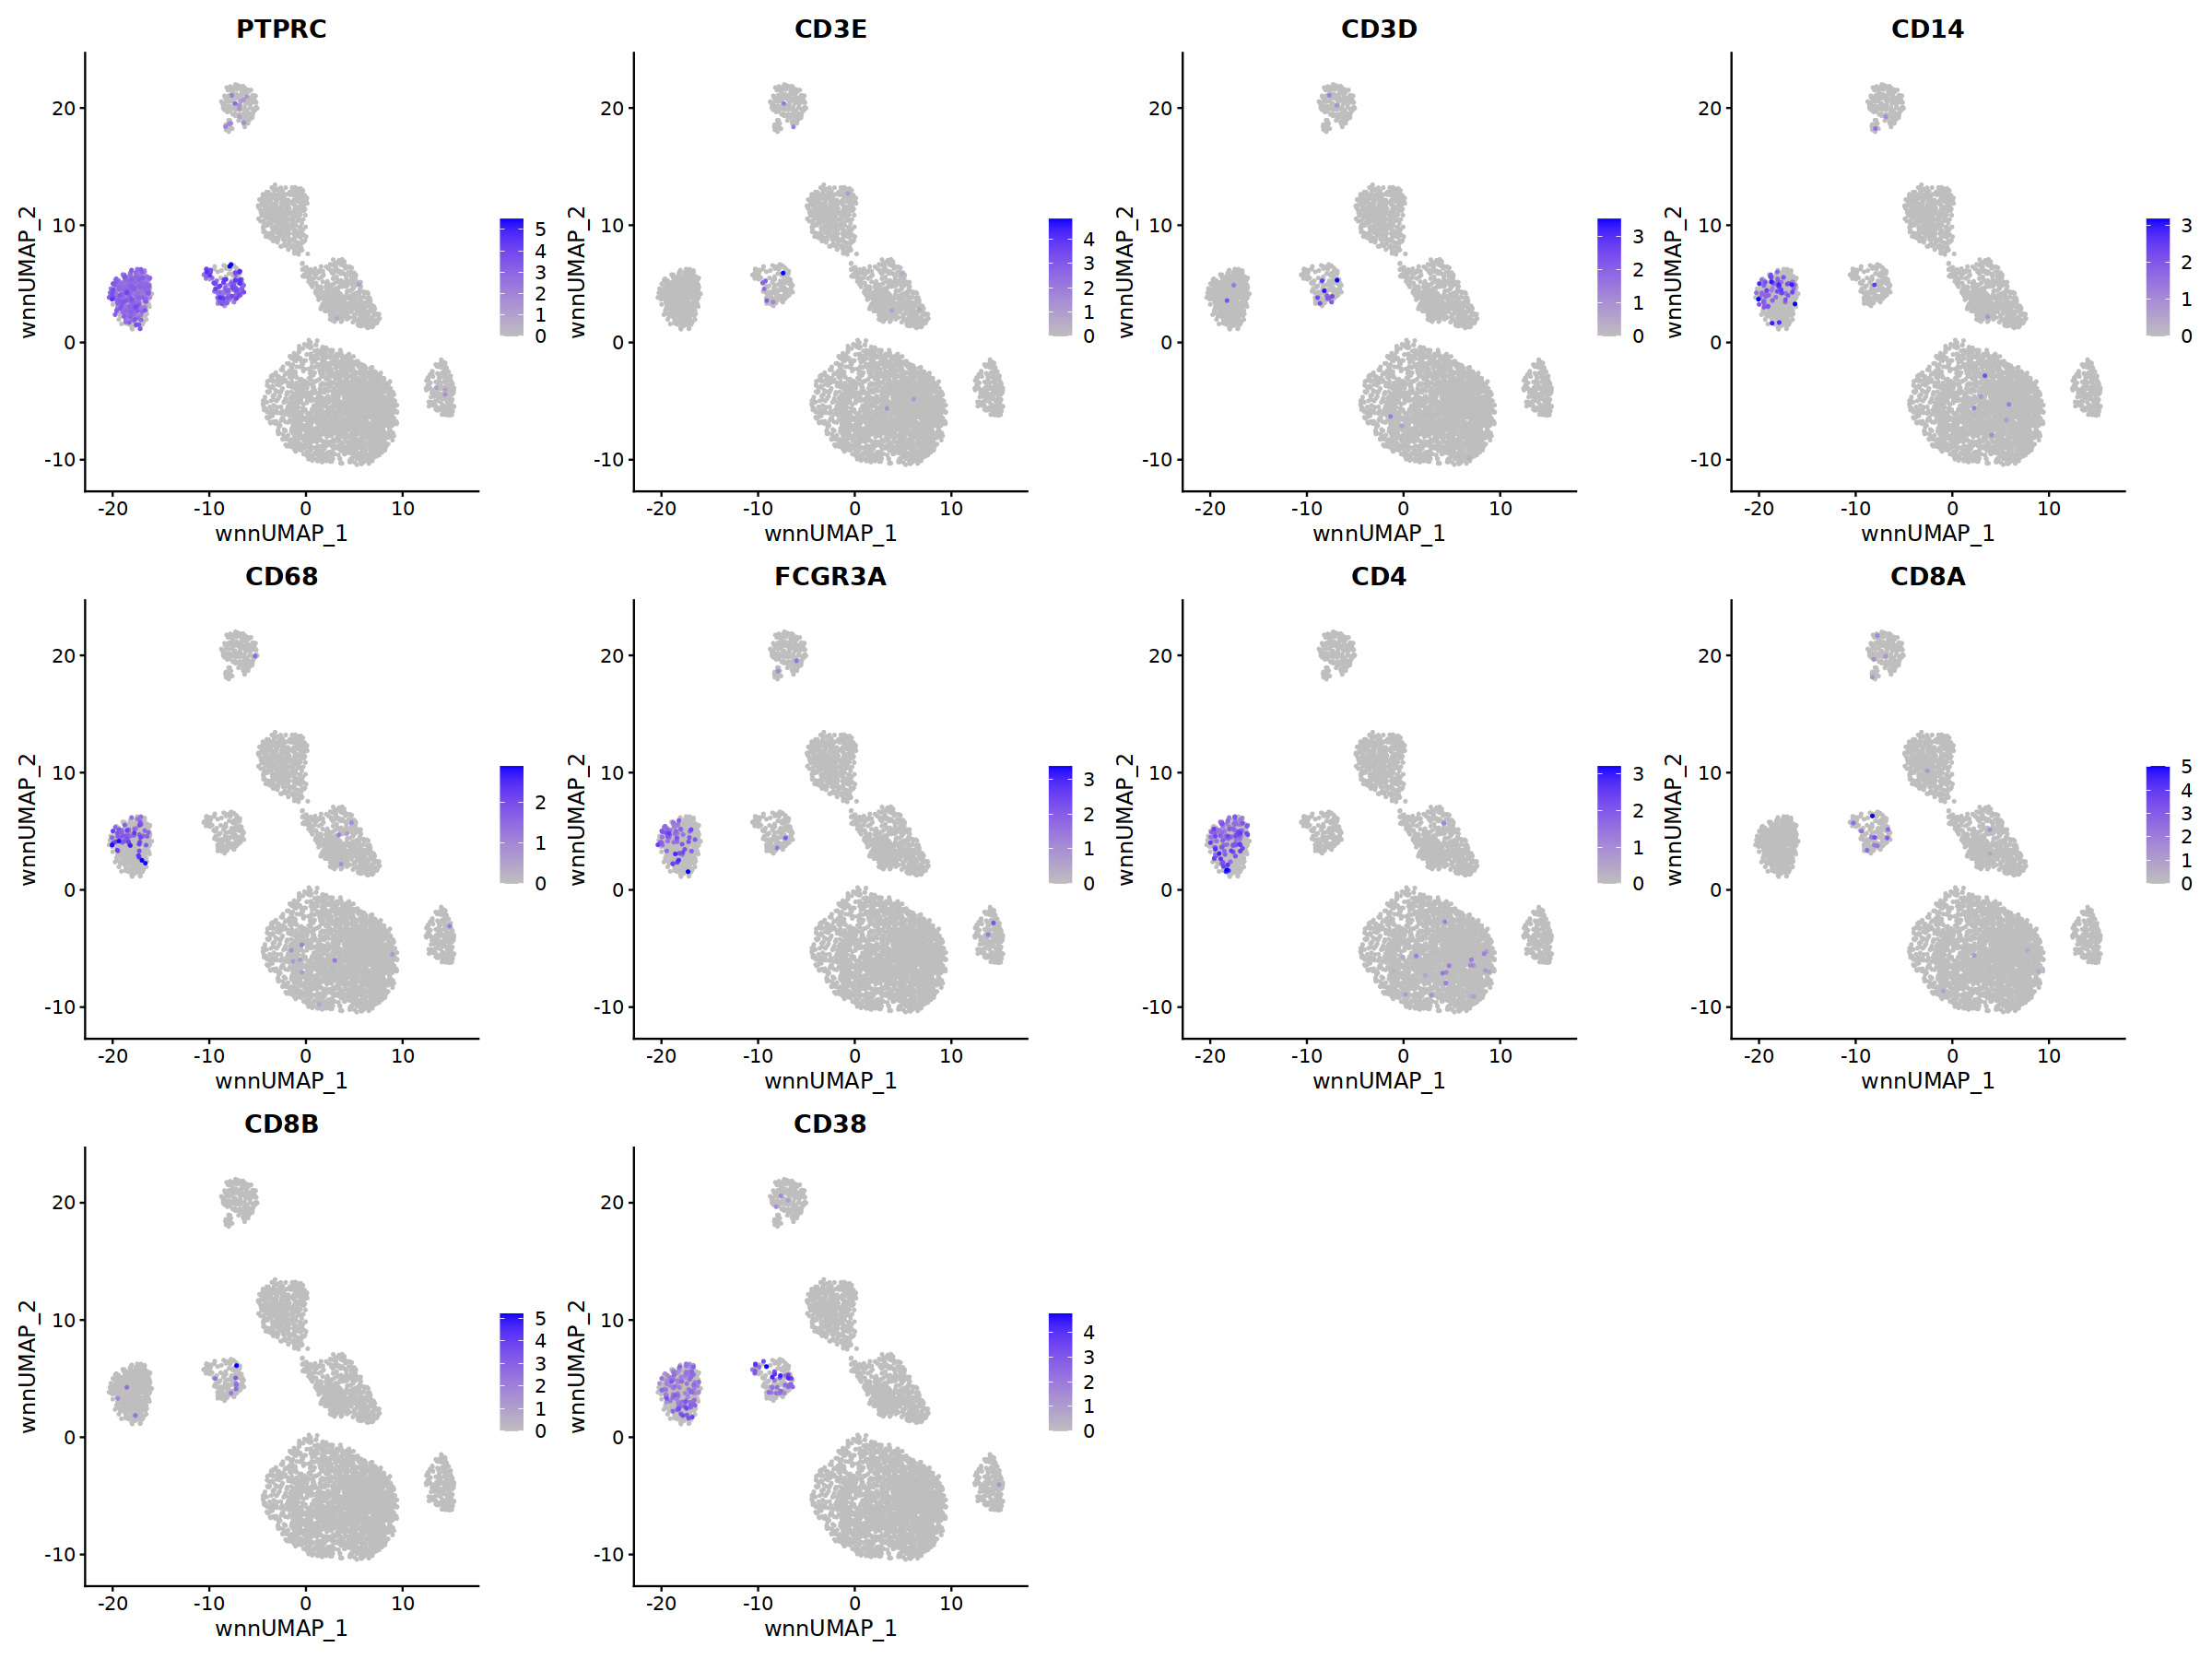

In [28]:
options(repr.plot.width = 20, repr.plot.height = 15)
immune <- c("PTPRC","CD3E", "CD3D", "CD14", "CD68", "FCGR3A", "CD4", "CD8A", "CD8B", "CD19", 
            "MS4A1", "CD38")

vars2plot <- exp_genes_plot(immune, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

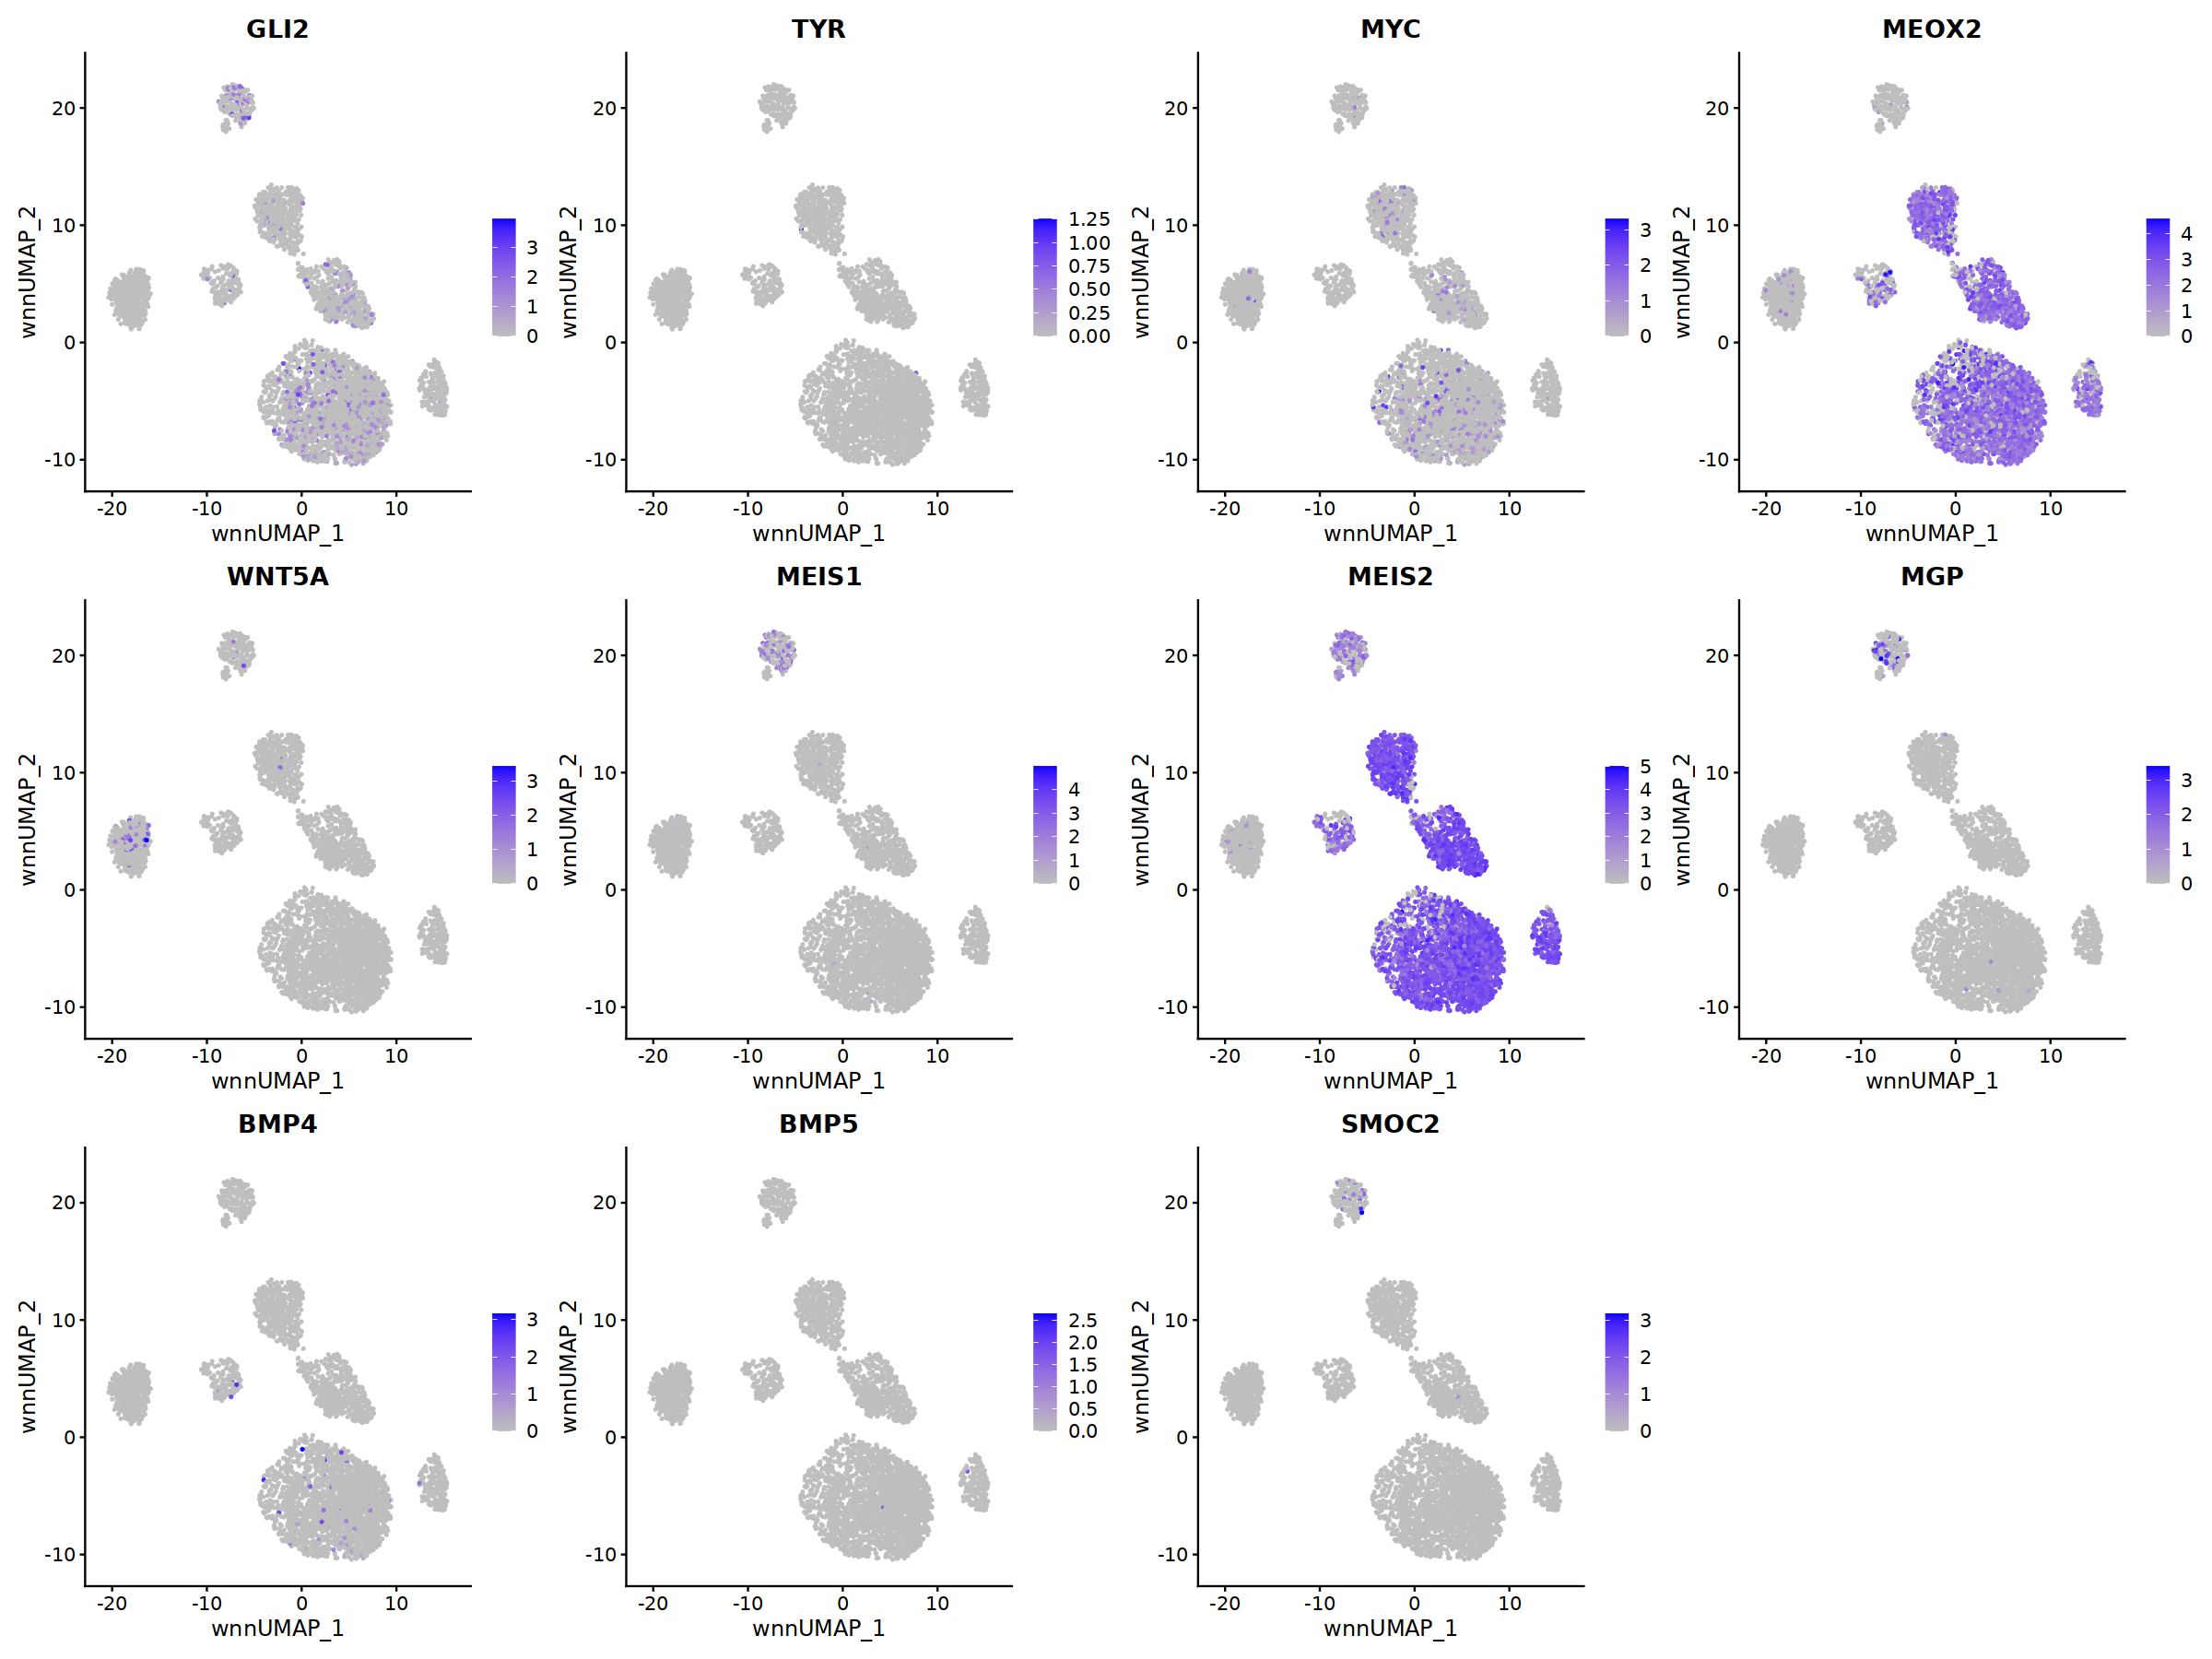

In [29]:
lite_tumor <- c("FABP7", "GLI2", "TYR", "MYC", "MEOX2", "WNT5A", "MEIS1", 
                "MEIS2", "MGP", "BMP4", "BMP5", "MYOC", "SMOC2")

vars2plot <- exp_genes_plot(lite_tumor, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"),  min.cutoff = 0)

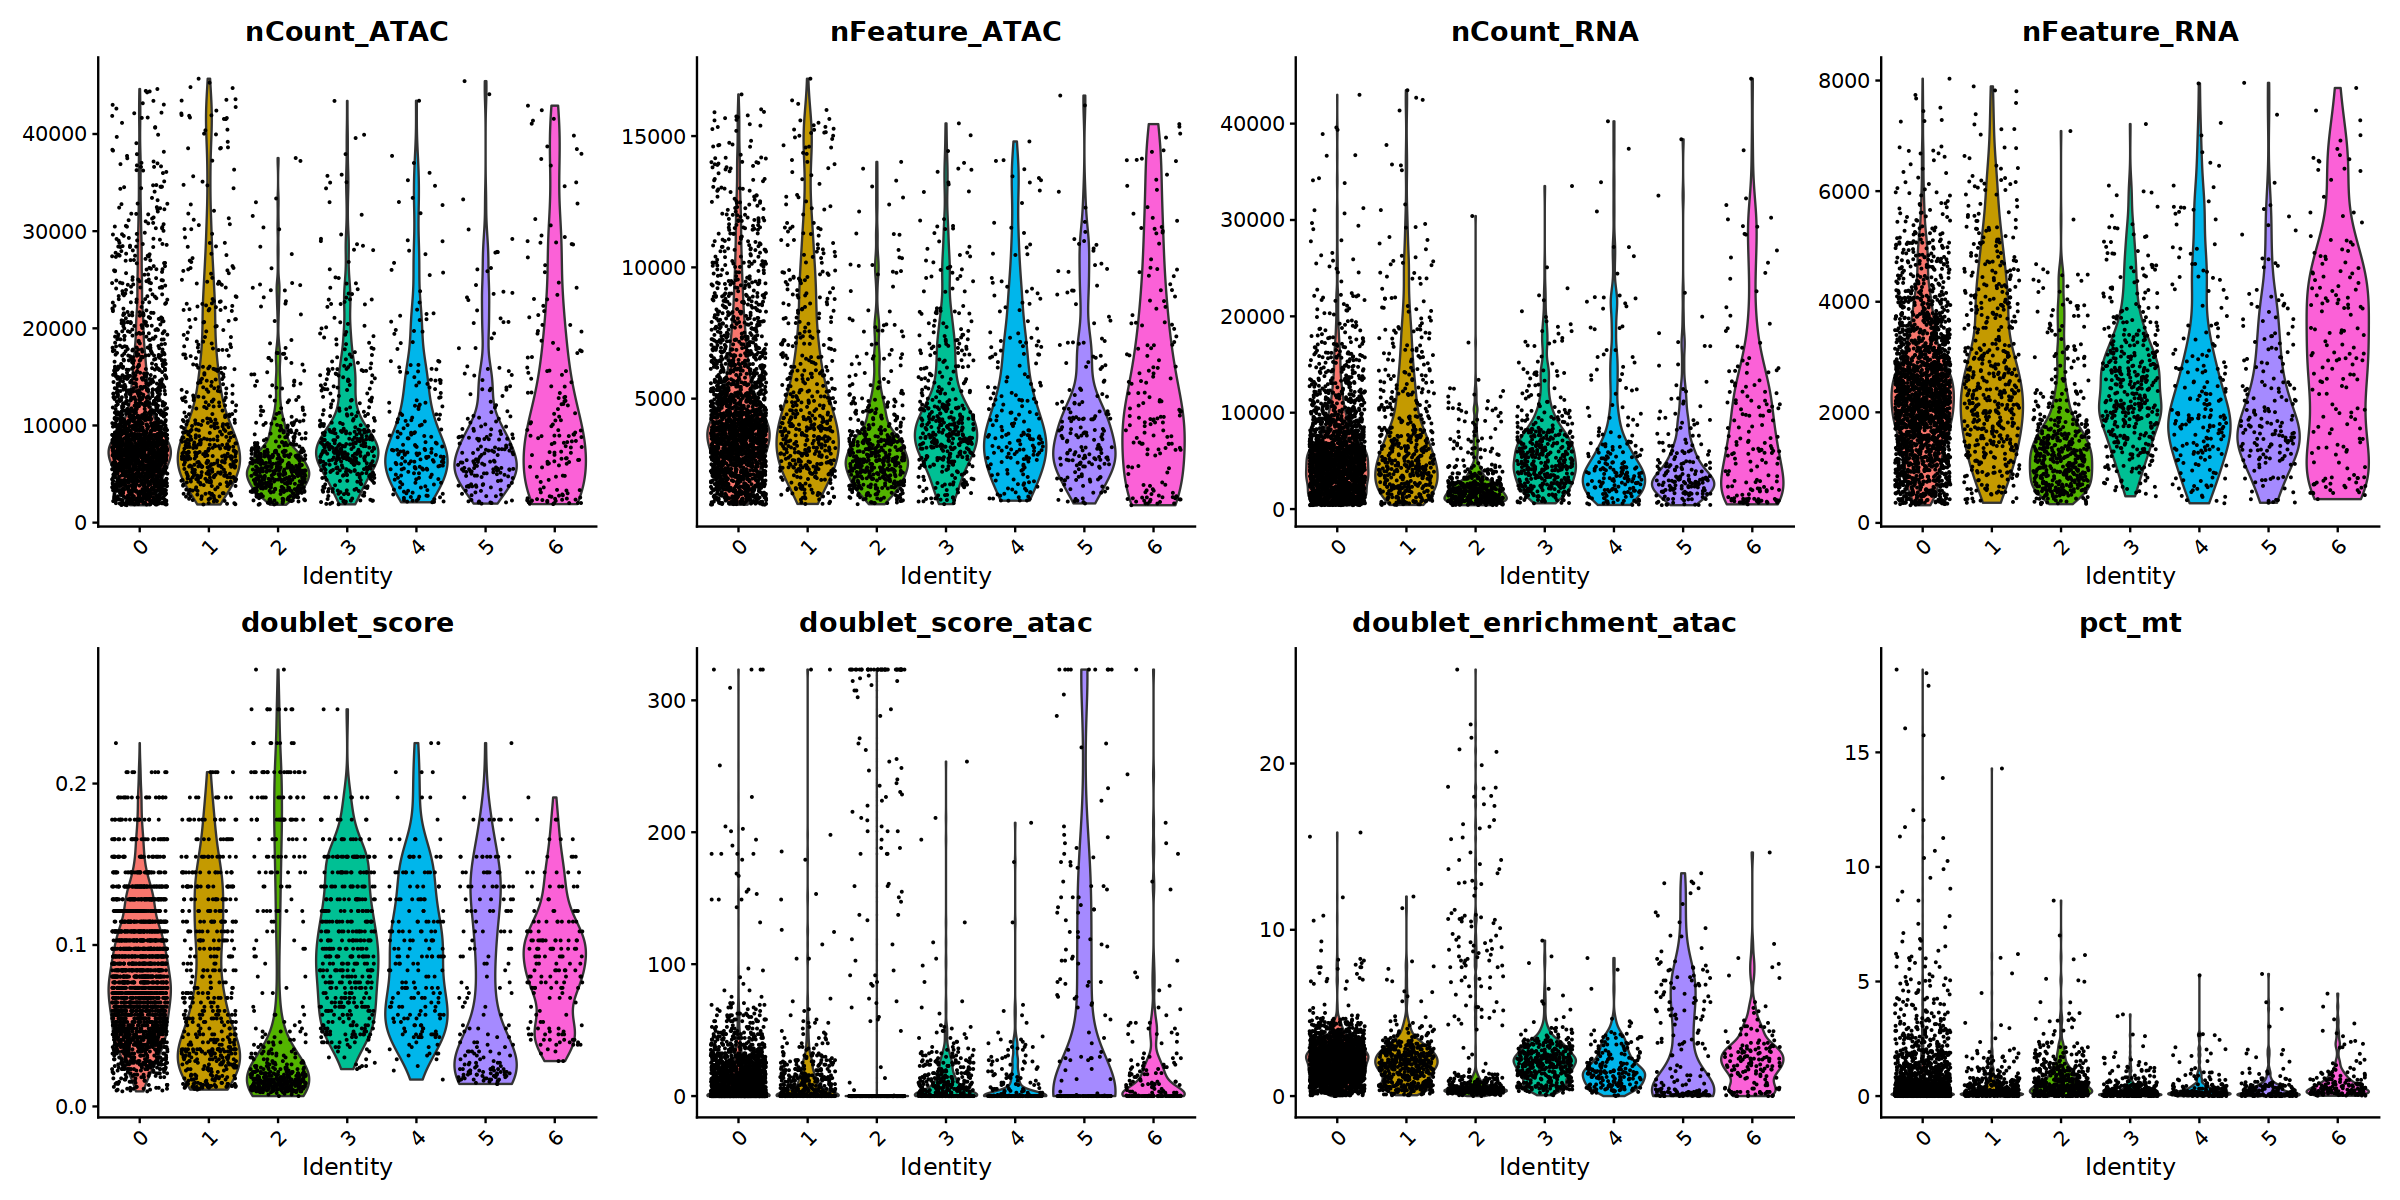

In [30]:
options(repr.plot.width = 20, repr.plot.height = 10)
qc_vars <- c('nCount_ATAC','nFeature_ATAC','nCount_RNA','nFeature_RNA',
             "doublet_score","doublet_score_atac",
             "doublet_enrichment_atac", "pct_mt")
VlnPlot(seurat_obj,feature=qc_vars, ncol = 4)

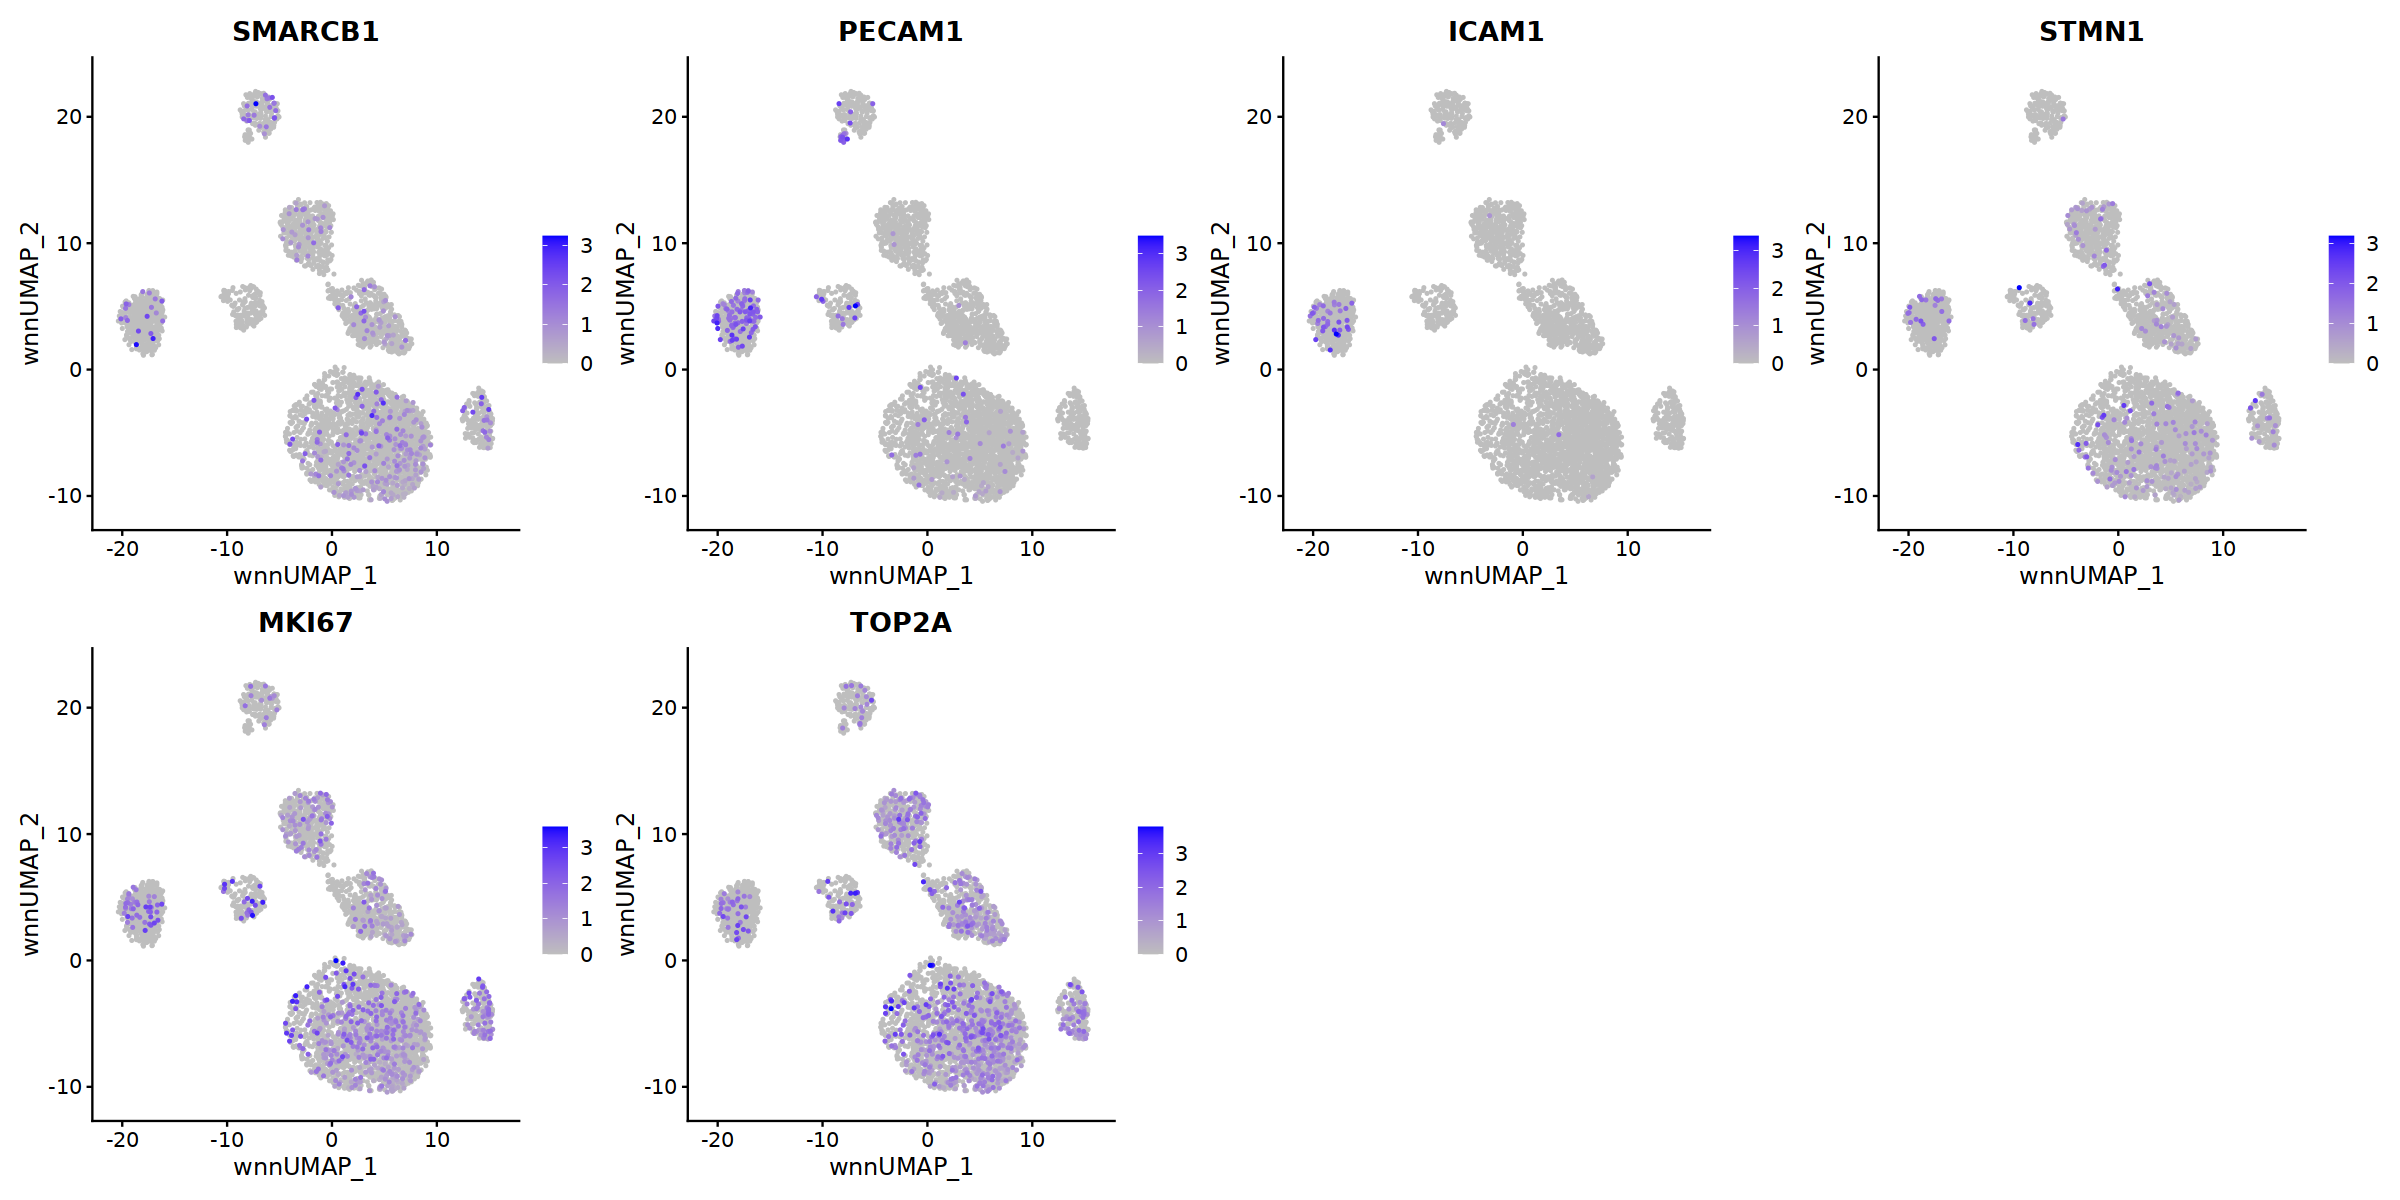

In [31]:
options(repr.plot.width = 20, repr.plot.height = 10)
other <- c("SMARCB1", "PECAM1","ICAM1","STMN1","MKI67","TOP2A")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=other, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

## Filter cells

There's still some unsolved RNA ambient in cluster 6 which has T-cell markers, those do not show clear signals to call them doublets

In [32]:
rna.markers %>% 
  dplyr::filter(cluster == "0") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=30)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
RALYL,7.454983e-214,3.126401,0.534,0.108,2.109164e-209,0,RALYL
LINC02232,8.271591e-238,2.035789,0.493,0.029,2.340199e-233,0,LINC02232
GALNTL6,2.457954e-164,1.978925,0.376,0.030,6.954043e-160,0,GALNTL6
PAPPA,2.931561e-236,1.700319,0.592,0.114,8.293972e-232,0,PAPPA
ANO5,1.539094e-276,1.672295,0.897,0.464,4.354405e-272,0,ANO5
PRELID2,1.026428e-259,1.629567,0.776,0.288,2.903970e-255,0,PRELID2
GCNT2,1.160660e-218,1.582638,0.733,0.263,3.283738e-214,0,GCNT2
GRIN2A,3.550468e-146,1.555557,0.566,0.199,1.004498e-141,0,GRIN2A
LINC02742,2.813002e-138,1.544792,0.701,0.348,7.958544e-134,0,LINC02742


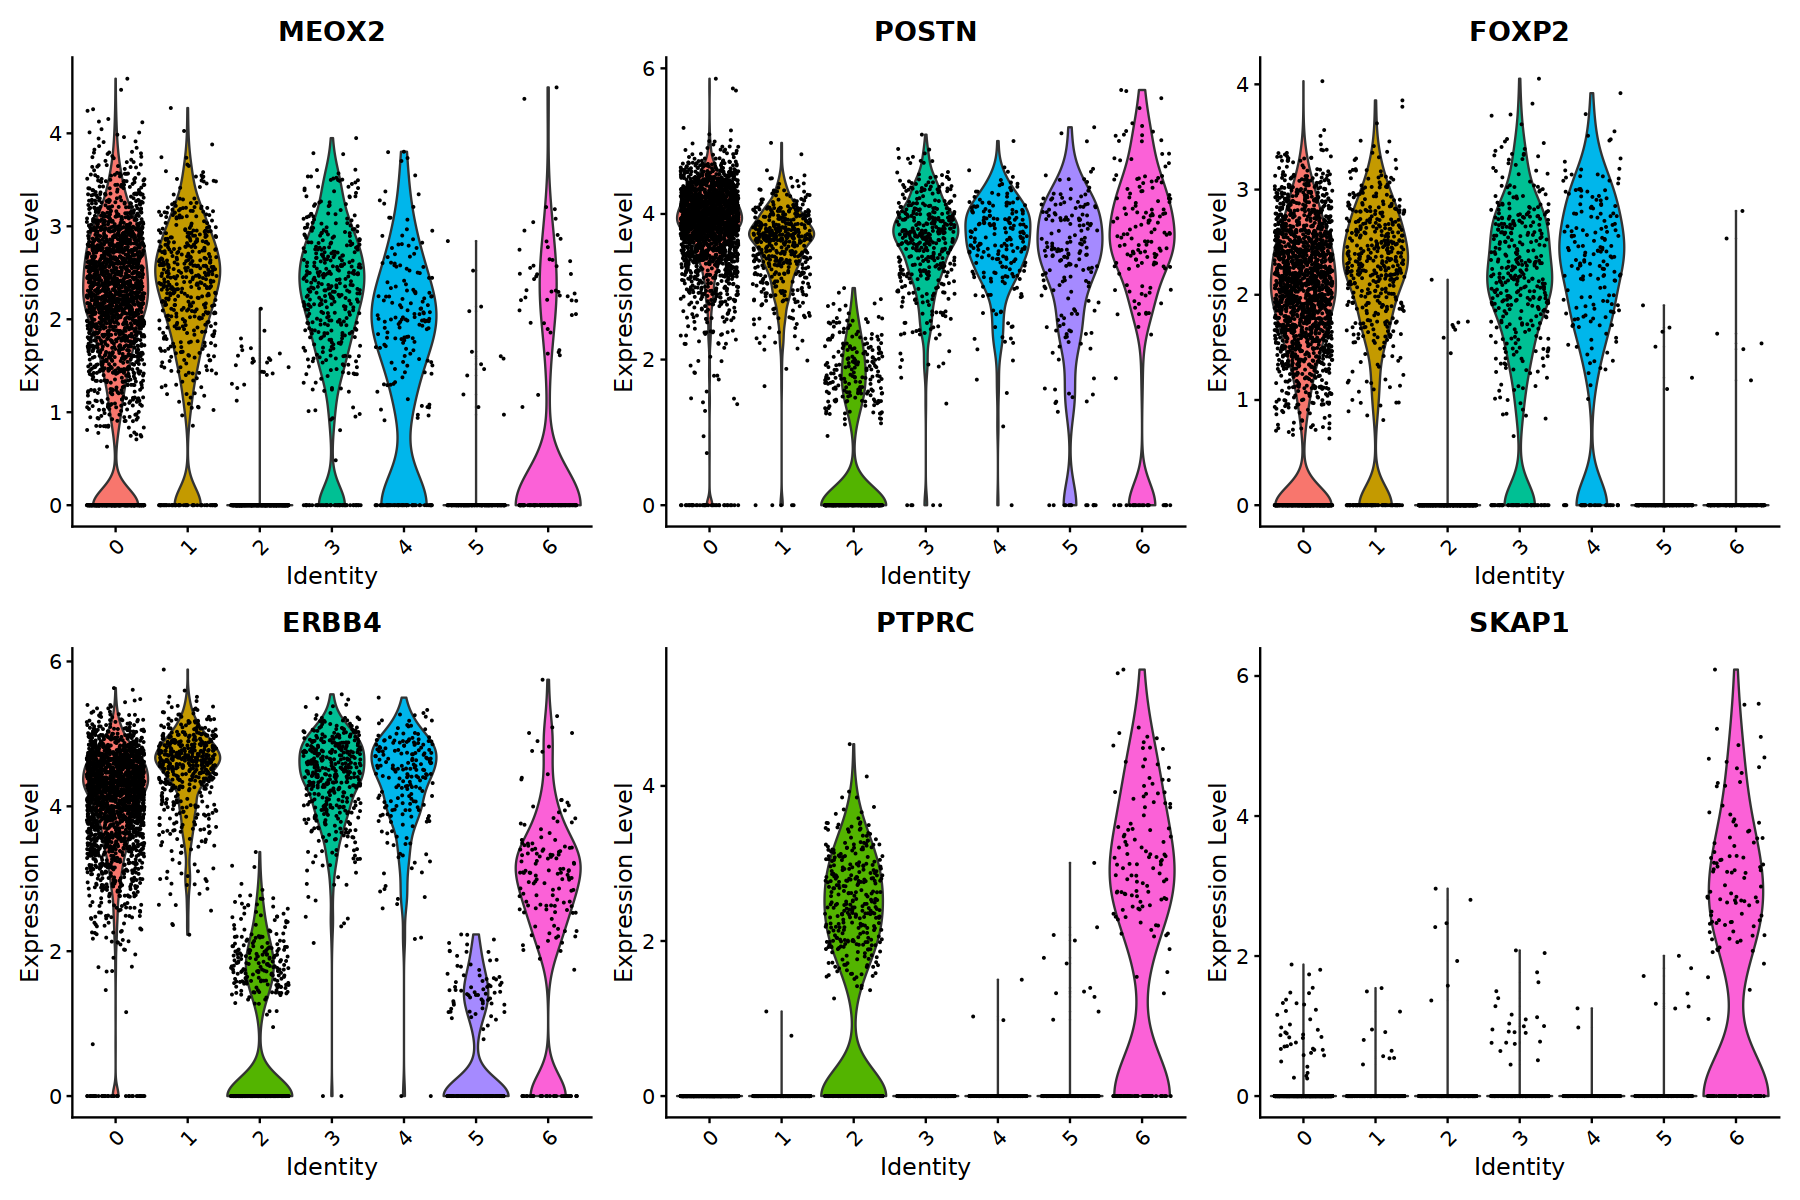

In [33]:
options(repr.plot.width = 15, repr.plot.height = 10, warn=-1,verbose = FALSE)
VlnPlot(seurat_obj,feature=c("MEOX2", "POSTN", "FOXP2", "ERBB4", "PTPRC", "SKAP1"), 
        ncol = 3)

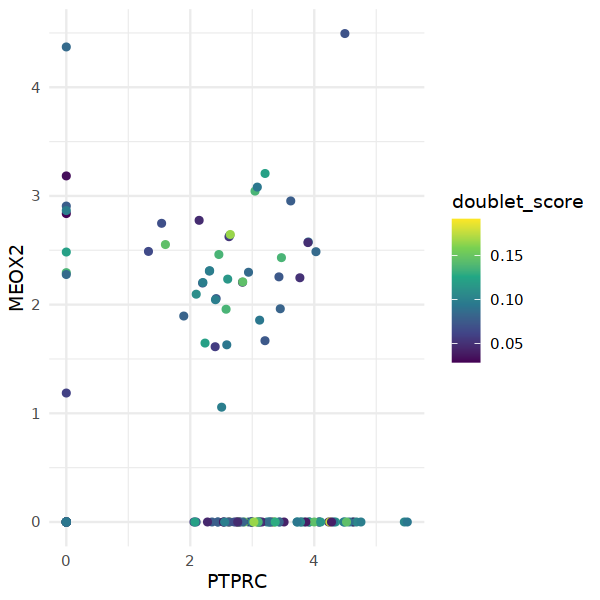

In [34]:
options(repr.plot.width = 5, repr.plot.height = 5)
data <- FetchData(seurat_obj, vars = c("seurat_clusters",
                                       "doublet_score_atac", "doublet_score",
                                       "MEOX2", "PTPRC", "POSTN",
                                       "SKAP1", "ERBB4"))
data <- data[data$seurat_clusters == 6, ]
ggplot(data, aes(x = PTPRC, y = MEOX2, color = doublet_score)) + 
  geom_point() +
  theme_minimal() +
  scale_color_viridis_c()

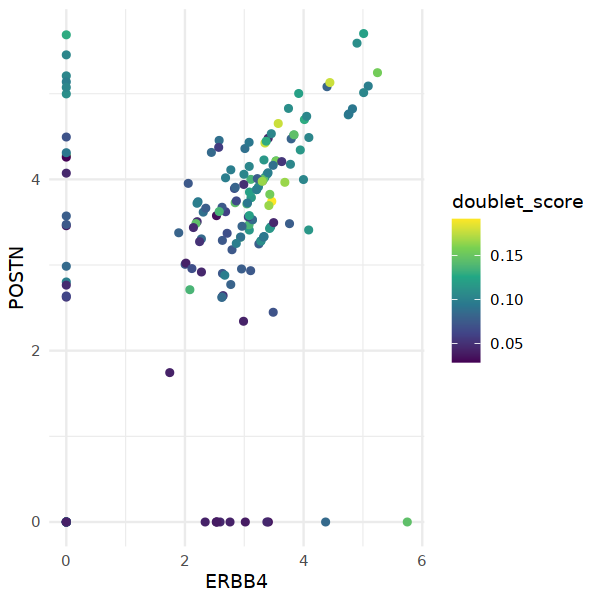

In [35]:
ggplot(data, aes(x = ERBB4, y = POSTN, color = doublet_score)) + 
  geom_point() +
  theme_minimal() +
  scale_color_viridis_c()

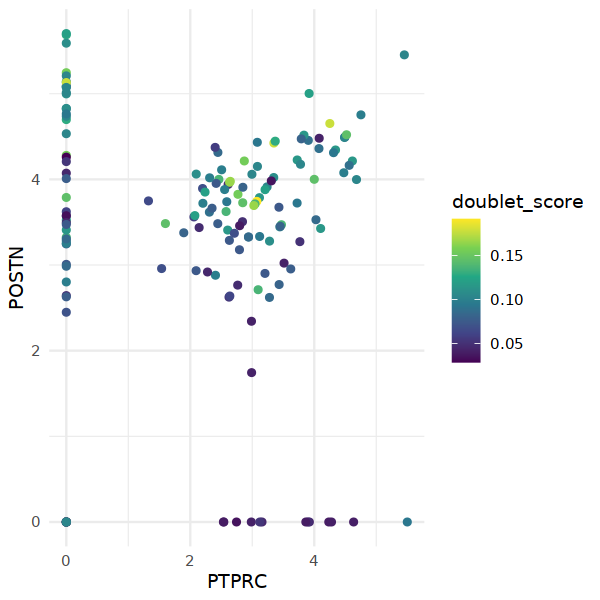

In [36]:
ggplot(data, aes(x = PTPRC, y = POSTN, color = doublet_score)) + 
  geom_point() +
  theme_minimal() +
  scale_color_viridis_c()

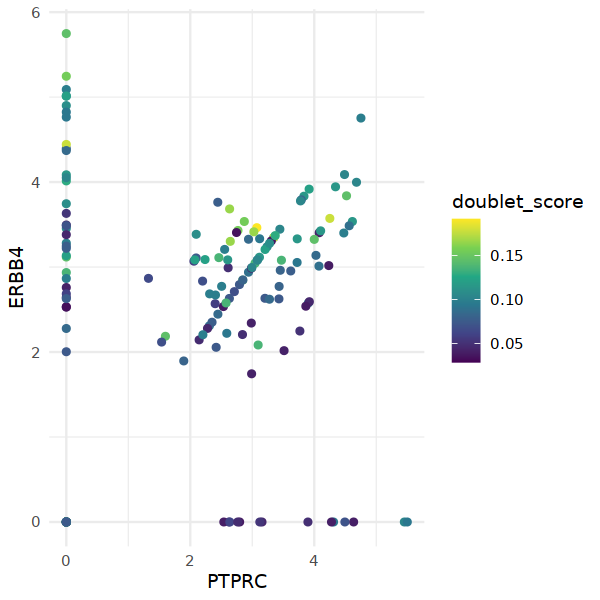

In [37]:
ggplot(data, aes(x = PTPRC, y = ERBB4, color = doublet_score)) + 
  geom_point() +
  theme_minimal() +
  scale_color_viridis_c()

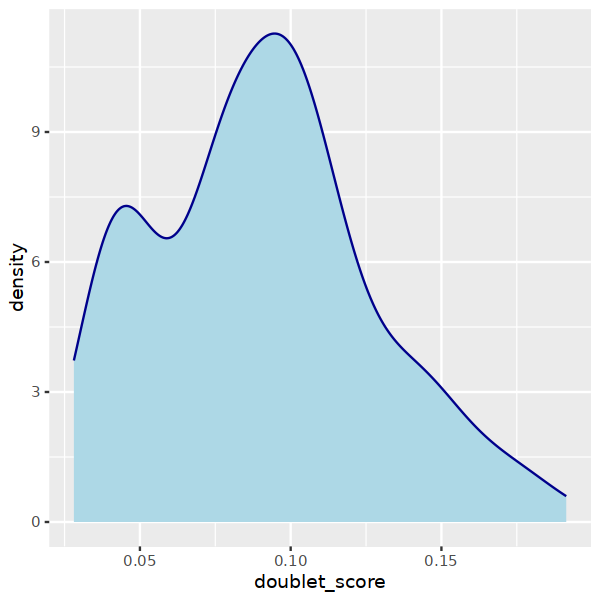

In [38]:
ggplot(data, aes(x=doublet_score))+
  geom_density(color="darkblue", fill="lightblue")

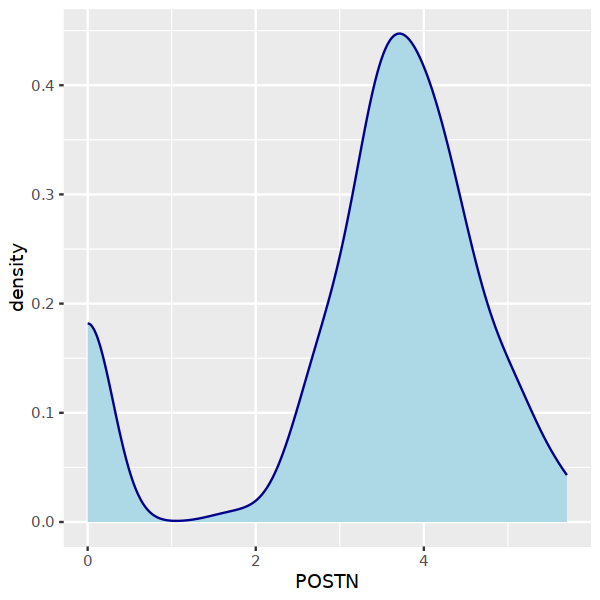

In [39]:
ggplot(data, aes(x=POSTN))+
  geom_density(color="darkblue", fill="lightblue")

In [40]:
dim(data)

[1] 160   8

In [41]:
dim(data[data$POSTN<0.2,])

[1] 22  8

Let's not filter further or we will loose to many cells on this cluster. Better deal with the noise in downstream analysis

### Rename

In [42]:
rename_clusters <- c("0"="Tumor SEMA3C", "1"="Tumor ROBO2",
                     "2"="Monocytes-Macrophages", "3"="Tumor TEAD1",
                     "4"="Tumor PTPRT", "5"="Fibroblast", "6"="T-cells")

seurat_obj <- RenameIdents(object = seurat_obj, rename_clusters)
seurat_obj$clusters <- Idents(seurat_obj)

In [43]:
cols_keep <- c('nCount_ATAC', 'nFeature_ATAC', 'nCount_RNA', 'nFeature_RNA', 
               'is_cell', 'atac_fragments', 'atac_peak_region_fragments', 
               'fragments', 'mononucleosomal', 'nucleosome_free', 'reads_count', 
               'FRiP', 'caller', 'nucleosome_signal', 'nucleosome_percentile', 
               'TSS.enrichment', 'TSS.percentile', 'high.tss', 'pct_mt', 
               'pct_ribosomal', 'doublet_score', 'doublet_pred', 'doublet_score_atac',
               'doublet_enrichment_atac', 'S.Score', 'G2M.Score', 'Phase',
               'RNA.weight', 'ATAC.weight', 'nCount_RNA_decontx','nFeature_RNA_decontx', 
               'RNA_decontx.weight','seurat_clusters','clusters')

seurat_obj@meta.data <- seurat_obj@meta.data[,cols_keep] 

In [44]:
rna.markers <- rna.markers %>% 
      mutate(cluster = as.character(cluster)) %>% 
      mutate(annotation = rename_clusters[cluster])

In [45]:
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.csv")))

In [46]:
df_meta <- seurat_obj@meta.data

df_meta <- df_meta %>% 
      mutate(cell_groups = case_when(
      str_detect(clusters, "Tumor") ~ "Tumor",
      clusters == "Immune Cells" | clusters == "T-cells" | clusters == 'Plasma B-cell' ~ "Immune",
      str_detect(clusters, "Macrophage") ~ "Immune",
      TRUE ~ "Other stromal"))

seurat_obj@meta.data$cell_groups <- df_meta$cell_groups

In [47]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$cell_groups)
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l1_anno_{patient}.csv")))

Calculating cluster Tumor

Calculating cluster Immune

Calculating cluster Other stromal



In [48]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

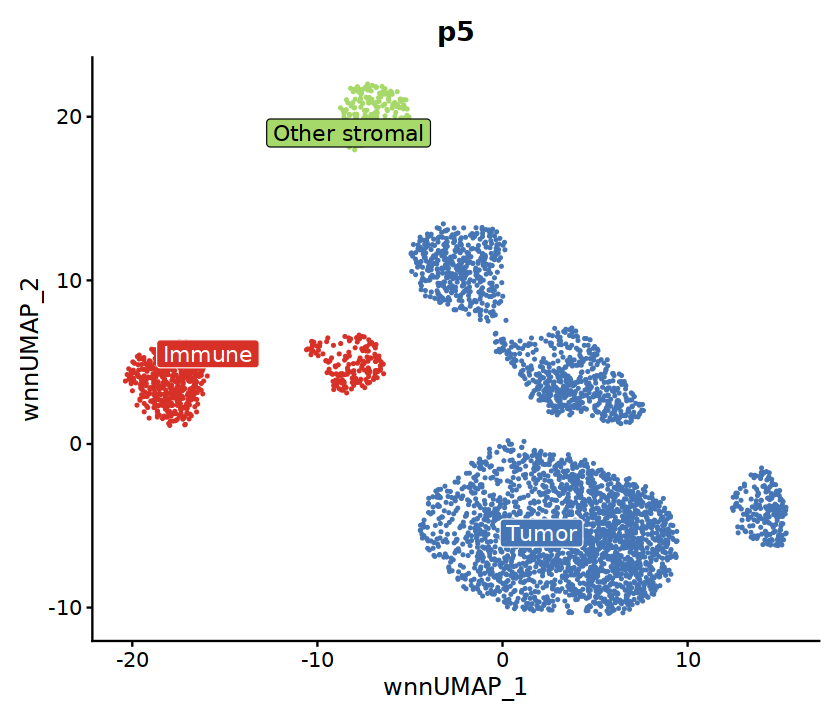

In [49]:
options(repr.plot.width = 7, repr.plot.height = 6)
l1 <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = c("Immune"="#d73027", "Other stromal"="#a6d96a","Tumor"="#4575b4")) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
l1

In [50]:
ggsave(plot = l1, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l1.svg")))

In [51]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$clusters)

In [52]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

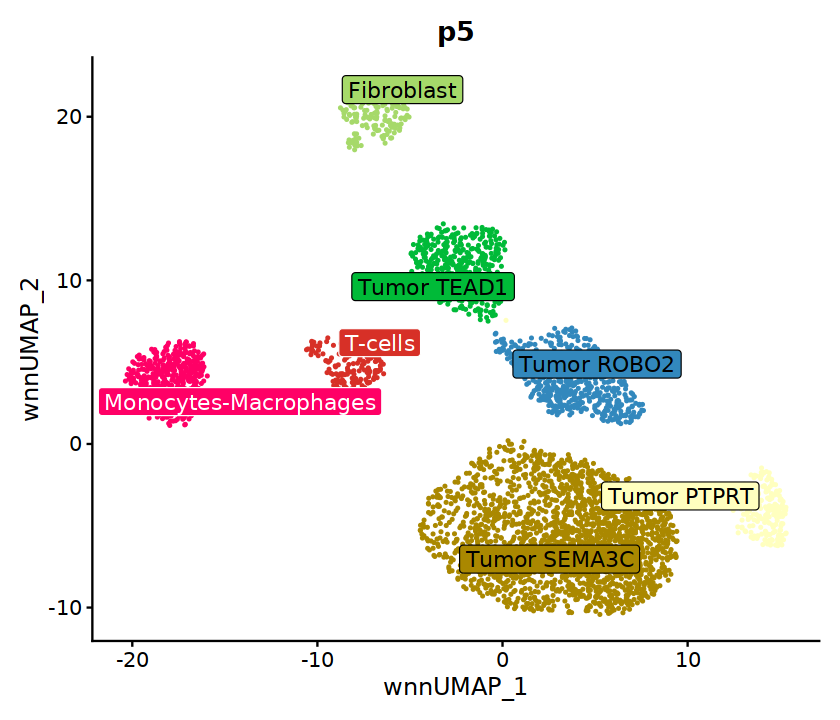

In [53]:
options(repr.plot.width = 7, repr.plot.height = 6)
p_clust <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))

p_clust

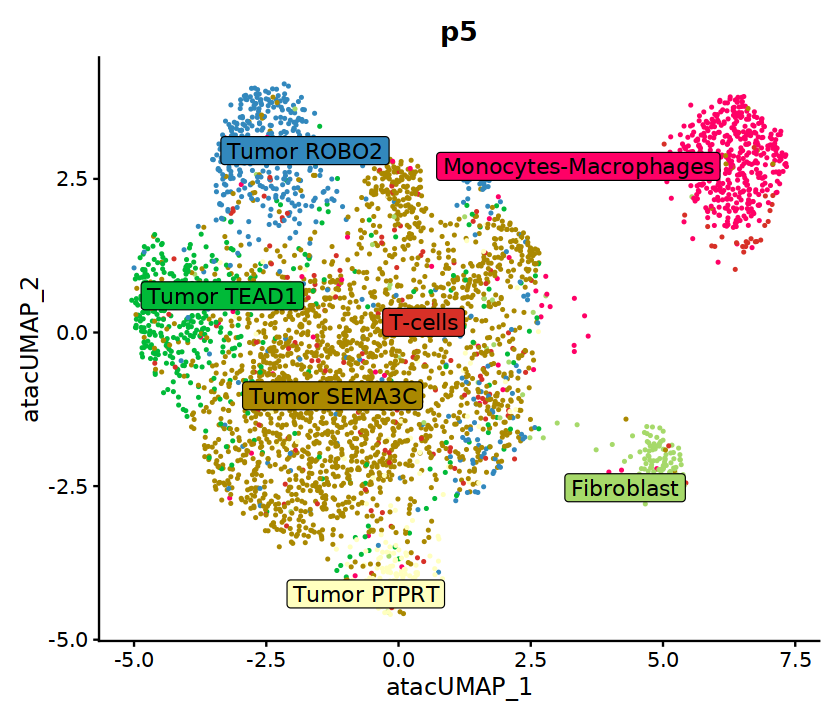

In [54]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(seurat_obj, 
        reduction = "umap.atac", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))


In [55]:
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP.svg")))
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l2.png")))

In [56]:
# Calculate the variance explained 
stdev <- Stdev(seurat_obj, reduction = "pca")

var_explained <- (stdev^2) / sum(stdev^2) * 100

pc1_label <- paste0("PC1: ", round(var_explained[1], 2), "% var.")
pc2_label <- paste0("PC2: ", round(var_explained[2], 2), "% var.")

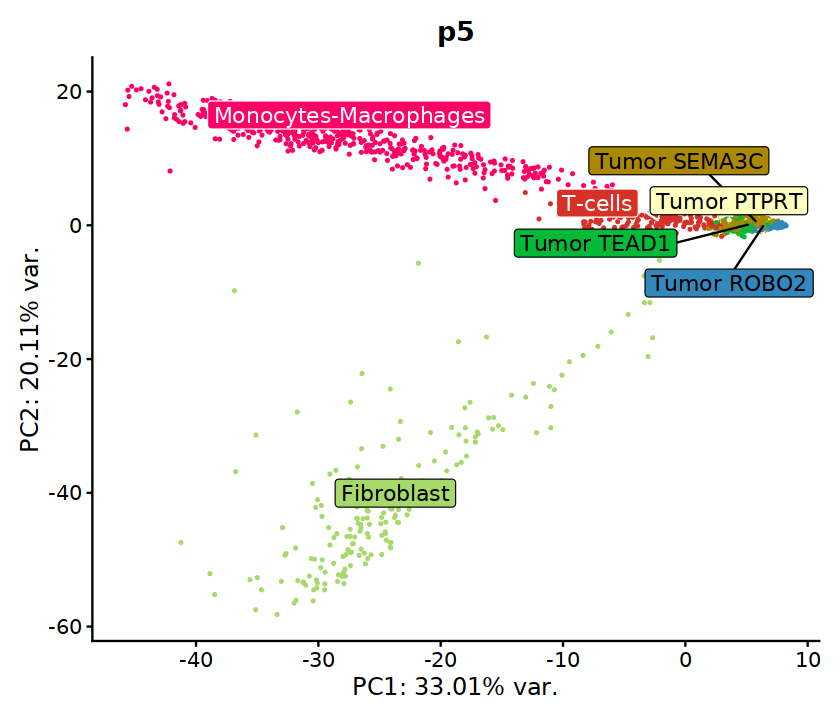

In [57]:
p_pca <- DimPlot(seurat_obj, 
        reduction = "pca", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    xlab(pc1_label) +
    ylab(pc2_label) +
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_pca 

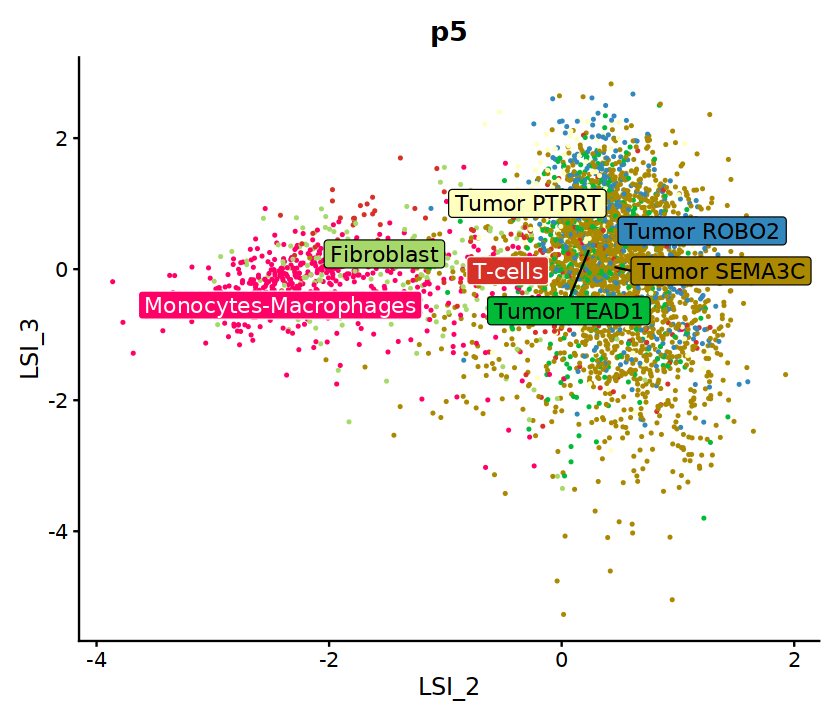

In [58]:
p_lsi <- DimPlot(seurat_obj, 
        reduction = "lsi.atac", 
        dims = c(2, 3),
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_lsi

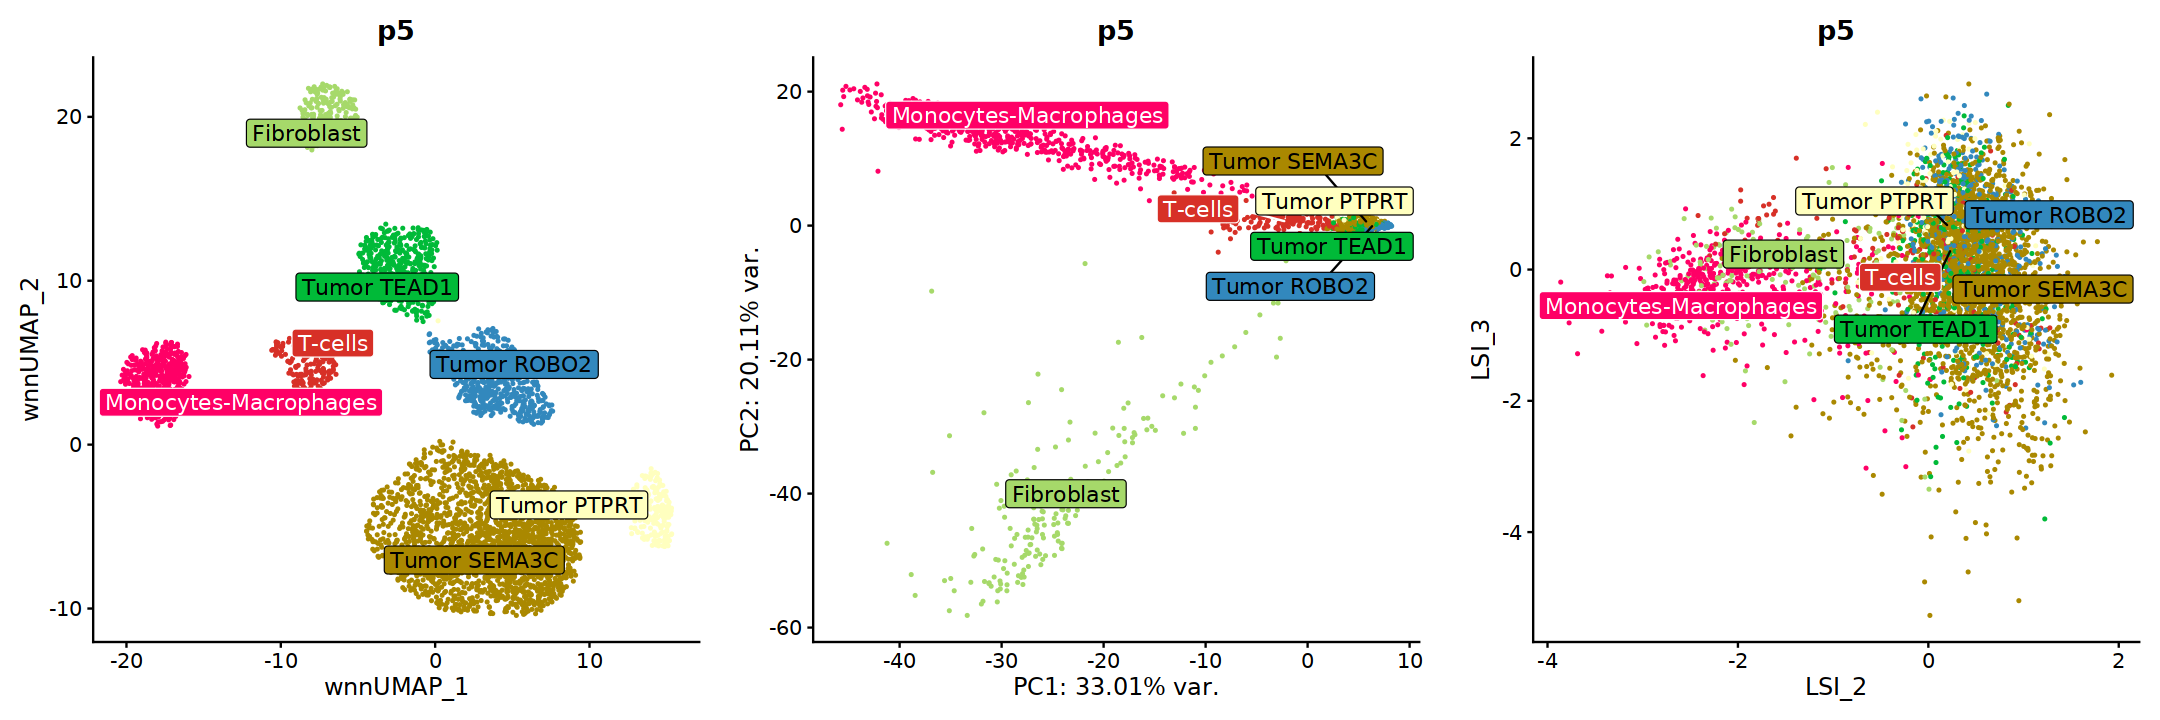

In [59]:
options(repr.plot.width = 18, repr.plot.height = 6)
cp <- cowplot::plot_grid(p_clust, p_pca, p_lsi,
                   align = "hv",
                   axis = "trbl",
                   ncol = 3,
                   nrow = 1)
cp

In [60]:
ggsave(plot = cp, width = 18, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_reductions.png")))

Pseudo-bulk per cluster

In [61]:
var_name <- paste0("markers_", patient)
markers_clust <- get(var_name)

markers <- unlist(markers_clust, use.names = F)
markers <- c(c("MEOX2", "POSTN", "FOXP2", "ERBB4"), markers) ## common markers to all clusters

In [62]:
Idents(seurat_obj) <- factor(Idents(seurat_obj), levels = names(markers_clust))

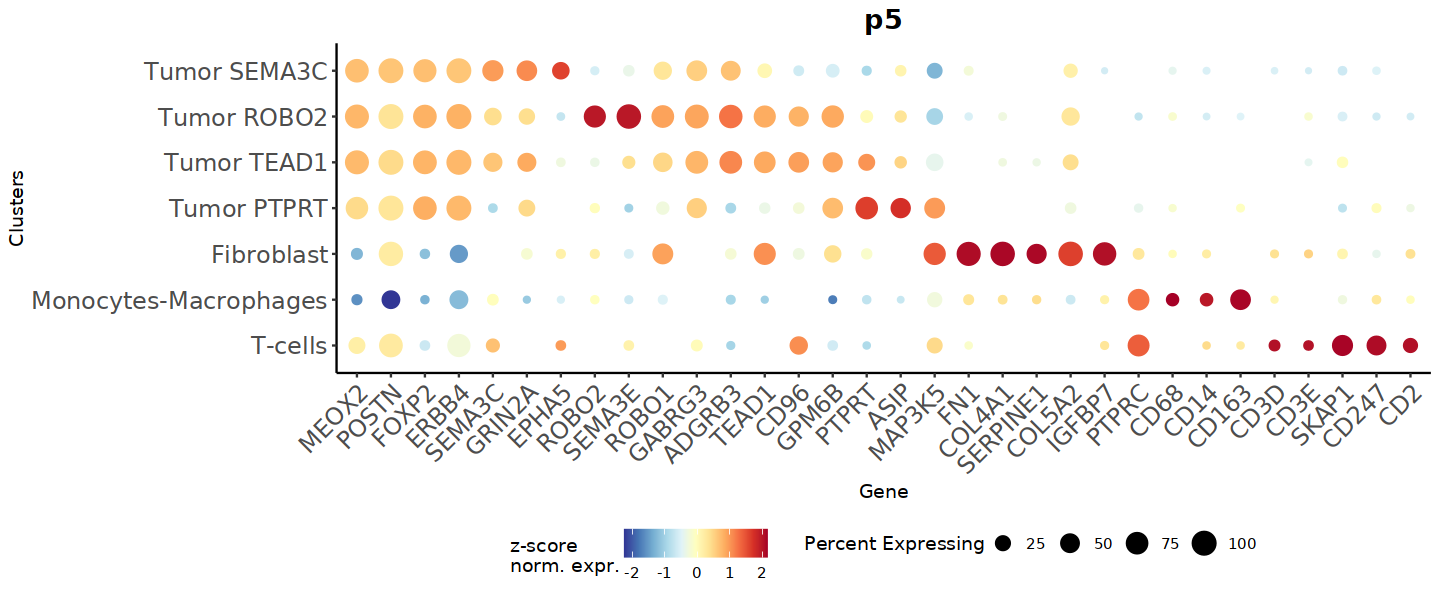

In [63]:
options(repr.plot.width = 12, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp1 <- custom_dp(seurat_obj, markers, TRUE,patient)
dp1

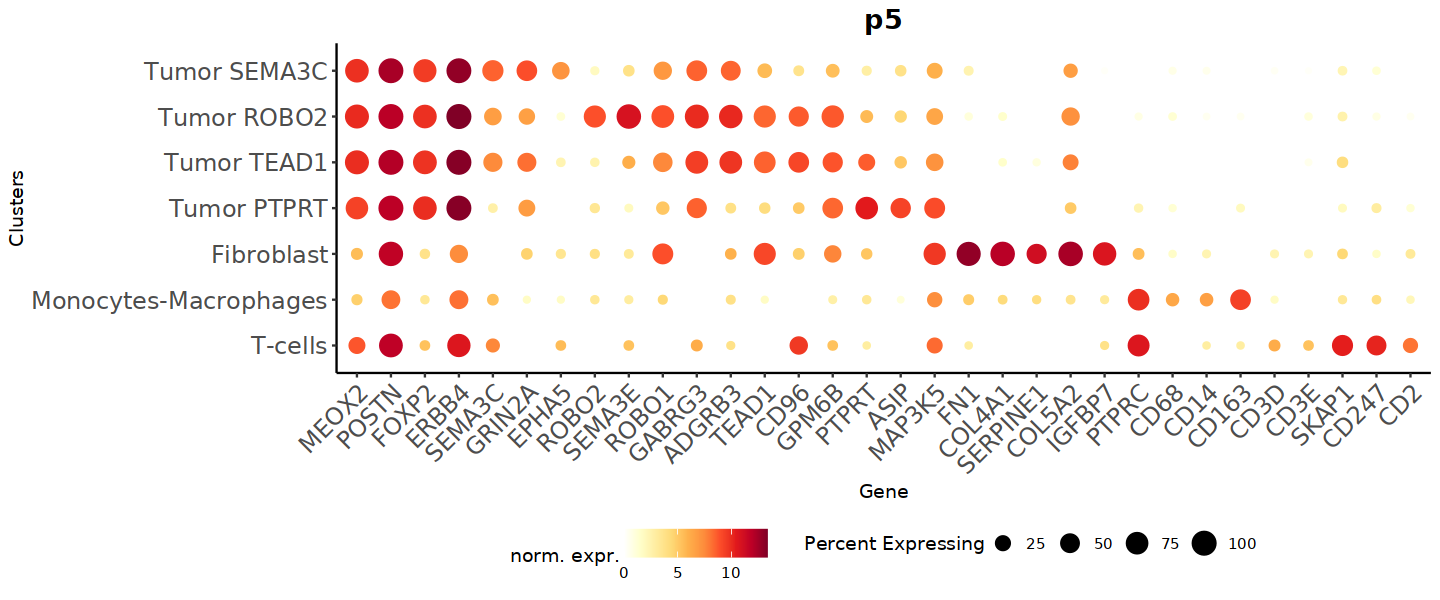

In [64]:
options(repr.plot.width = 12, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp2 <- custom_dp(seurat_obj, markers, FALSE,patient)
dp2

In [65]:
ggsave(plot = dp1, width = 12, height = 5, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_dotplot.svg")))
ggsave(plot = dp1, width = 12, height = 5, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_dotplot.png")))

## Save

In [66]:
# keep original metrics
seurat_obj$ncount_rna <- seurat_obj$nCount_RNA
seurat_obj$nfeature_rna <- seurat_obj$nFeature_RNA

In [67]:
seurat_obj$RNA <- NULL
seurat_obj[['RNA']] = seurat_obj[[assay_ch]]
DefaultAssay(seurat_obj) <- "RNA"
seurat_obj$RNA_decontx <- NULL

In [68]:
saveRDS(seurat_obj, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.rds")))

## Session

In [69]:
sessionInfo()

R version 4.1.1 (2021-08-10)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: CentOS Linux 7 (Core)

Matrix products: default
BLAS/LAPACK: /home/groups/singlecell/isentis/conda_envs/ines_r4.1.1c/lib/libopenblasp-r0.3.24.so

locale:
 [1] LC_CTYPE=es_ES.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=es_ES.UTF-8        LC_COLLATE=es_ES.UTF-8    
 [5] LC_MONETARY=es_ES.UTF-8    LC_MESSAGES=es_ES.UTF-8   
 [7] LC_PAPER=es_ES.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=es_ES.UTF-8 LC_IDENTIFICATION=C       

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] scater_1.22.0               scran_1.22.1               
 [3] scuttle_1.4.0               SingleCellExperiment_1.16.0
 [5] SummarizedExperiment_1.24.0 Biobase_2.54.0             
 [7] GenomicRanges_1.46.1        GenomeInfoDb_1.30.1        
 [9] IRanges_2.28.0    